# v6：(1) PCA 原点改为胸鳍中点；(2) FM quick circle 检测 A（距离）/ B（6 变量微状态）/ C（6 变量 + Infomap）

**全部建立在 v3b 上**：只读 v3b（`20261108_pair_state6d_clean_sw11_v3b`）保存的中间结果，不重新做预处理、分格或 Infomap，所以帧、清洗（去异常骨架、≤ 5 帧插值、SG 11 帧平滑）、训练 / 测试划分（训练 K_1_1、K_1_2、P_1_1、P_1_2；测试 K_1_3、P_1_3）、BORIS 标签规则都和 v3b 完全一致。

**(1) PCA 原点**：v3b 的 PCA 每帧减去 6 个点的平均（质心）。v6 改成减去两条鱼胸鳍点的中点 O = (pec_a + pec_b) / 2，其余不变：同样按水平 pec → pec 方向转到 +x，同样的 14 个输入坐标（a 的嘴、尾，b 的嘴、尾的 x'y'z'，b 的胸鳍 x'、z'），同样的帧，只用训练集拟合。FM（a = F，FM1 与 FM2 合并）和 MM（M1M2）分别做。比较 PC1、PC2 的方差贡献率，以及 PC 得分和 Δz、D_xy 的相关。PC 的正负号可以任意翻转，所以比较 |r|。

**(2) quick circle：A / B / C**（FM，qc = quick circle + incomplete qc + Courtship；负例 = none + att + wrap；unknown 不计）：

| | 打分单位 | 来源 |
|---|---|---|
| A | 3D 胸鳍距离的 2 mm 格子 | v3b 已有（距离基线） |
| B | 6 变量微状态（v3b 的 16129 个状态，不经 Infomap） | **v6 新增** |
| C | B 的微状态经 Infomap（τ = 25 帧，v3b 训练集 LOEO 为 FM qc 选出的 τ）合成的簇 | v3b 已有 |
| C 的其他 τ（参照） | 同上，τ = 1、5、7、17、50 | 7、17、50 读 v3b；1、5 本 notebook 新跑 Infomap |

三种方法用同一套流程：训练集上每个单位的分数 = P(qc | 单位)，用 50 个伪帧向训练集整体 qc 比例收缩（观测少的单位分数接近整体比例；测试中出现、训练中没有的单位 = 整体比例）；没有状态的帧（审核屏蔽、跟踪丢失）是一个单独的单位；配对内居中平均 124 帧；阈值 = 训练集上 F1 最大的值，测试固定使用。

**(3) 攻击**（Step 3）：MM 的 att（attack + attempted att + Dash）用和 (2) 完全相同的 A / B / C 流程（C 的主 τ = 7，v3b 训练集选出的）。

**(5) 新测试视频 E_1_1**（Step 2-extra）：E 组不在训练集里（新个体）。按 v3b 的预处理和分格重新计算后，作为第三个测试视频加入 Step 2–4 的所有表和图；打分器仍只在训练集上拟合。

**(4) 误差分析**（Step 4）：qc 和 att 的误报帧离 BORIS 区间多远、漏报帧怎么漏的、不同长度 bout 的检出率，以及整段视频的时间轴图。

**输出目录**：`<runs_dir>/behavior_features/outputs/20261109_pca_origin_qc_abc_v6/`。

## 参数

`SOURCE_RUN` = 读入的 v3b 输出目录。`TARGETS` = 每个检测类别的设置（单元、C 的主 τ 和参照 τ、平滑窗口、每个视频评估哪些配对、误差分析的 bout 时长分组）。平滑窗口、`PRIOR_FRAMES`、`DIST_BIN_MM`、`DIST_MAX_MM`、Infomap 设置和 v3b 相同。

In [1]:
# ============================== Parameters ==============================
from pathlib import Path

RUN_NAME = "20261109_pca_origin_qc_abc_v6"
SOURCE_RUN = "20261108_pair_state6d_clean_sw11_v3b"
OUTPUT_ROOT = None       # None -> <runs_dir>/behavior_features/outputs (paths config)
TRAIN_EXPERIMENTS = ["20251225_K_1_1_FCMC", "20251225_K_1_2_FCMC", "20260112_P_1_1_FCMC", "20260113_P_1_2_FCMC"]
TEST_EXPERIMENTS = ["20251225_K_1_3_FCMC", "20260112_P_1_3_FCMC"]
# Extra test videos for Step 2-4 (not in v3b): preprocessed here exactly as v3b Step 0 and binned with the
# v3b bin edges; scored with the detectors fitted on TRAIN_EXPERIMENTS. E = a group not in the training set.
EXTRA_TEST_EXPERIMENTS = ["20251220_E_1_1_FCMC"]
UNITS = {"FM": [("F", "M1"), ("F", "M2")], "MM": [("M1", "M2"), ("M2", "M1")]}
DPI = 200
THUMB_WIDTH = 900

# --- Part 1: PCA origin
PCA_UNITS = {"FM": ["FM1", "FM2"], "MM": ["M1M2"]}   # as v3b Step 0b
ORIGINS = ["centroid", "pec_mid"]                     # centroid = v3b (mean of 6 points); pec_mid = (pec_a + pec_b) / 2
PCA_SHOW = 8

# --- Part 2: qc detection A / B / C (FM)
LABEL_CLASSES = {
    "wrap": ["wrap"],
    "qc": ["quick circle", "incomplete qc", "courtship"],
    "att": ["attack", "attempted att", "dash"],
}
# One entry per detection target. tau = main C (v3b leave-one-experiment-out choice on the training set);
# taus_extra = also reported (reference only); ref_tau = reference C drawn in the main figures;
# smooth = v3b smoothing (frames); eval_copies = ordered pairs evaluated per test video (MM: one order only,
# the other order is the same two fish); bout_bins_s = bout-duration bins for the error analysis.
TARGETS = {
    "qc": {"unit": "FM", "step": "02", "tau": 25, "taus_extra": [1, 5, 7, 17, 50], "ref_tau": 7, "smooth": 124,
           "eval_copies": ["FM1", "FM2"], "bout_bins_s": [0, 0.75, 1.5, 3.0, 1e9], "zoom_s": 60.0},
    "att": {"unit": "MM", "step": "03", "tau": 7, "taus_extra": [1, 3, 5, 17, 20], "ref_tau": 3, "smooth": 5,
            "eval_copies": ["M1M2"], "bout_bins_s": [0, 0.1, 0.3, 1.0, 1e9], "zoom_s": 20.0},
}
FP_DIST_S = [0.5, 2.0]   # error analysis: false-positive frames within / beyond these distances of a BORIS bout
# Infomap for taus that v3b did not save (same settings as v3b Step 3)
N_TRIALS = 200
INFOMAP_SEED = 20261107
KEEP_SELF_LOOPS = True
INFOMAP_WORKERS = 6
PRIOR_FRAMES = 50.0      # shrinkage towards the overall train qc rate (all three methods)
DIST_BIN_MM = 2.0
DIST_MAX_MM = 300.0

PARAMETERS = {k: (str(v) if isinstance(v, Path) else v) for k, v in dict(globals()).items()
              if k.isupper() and k != "PARAMETERS"}
print(f"{len(PARAMETERS)} parameters; run {RUN_NAME}; source {SOURCE_RUN}")

22 parameters; run 20261109_pca_origin_qc_abc_v6; source 20261108_pair_state6d_clean_sw11_v3b


## Setup（公共函数，不是分析步骤）

找仓库根目录、读路径配置、建输出目录。`src_file` 在 v3b 的 `data/` 里找唯一匹配的文件，找不到或不唯一就报错。新增的计算逻辑是 `scripts/analysis/microstate.py` 的 `align_pair(..., origin="pec_mid")` 和 `recentre_pec_mid`（单元测试 `tests/test_microstate_pose.py`：两种做法结果相同）。

In [2]:
import os
import sys
import time
import json
import platform

REPO = Path.cwd().resolve()
while not (REPO / "pyproject.toml").exists():
    if REPO.parent == REPO:
        raise RuntimeError("repository root (pyproject.toml) not found above the working directory")
    REPO = REPO.parent
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as IPImage, display
from sklearn.metrics import average_precision_score, precision_recall_curve

from scripts.analysis import microstate as M
from scripts.analysis import pose_states as S
from scripts.analysis import pair_state4d as P4
from scripts.analysis.behavior_dataset import resolve_roots

_CONFIG, REVIEW_ROOT, _BF_ROOT = resolve_roots(None)
OUT_ROOT = Path(OUTPUT_ROOT) if OUTPUT_ROOT else Path(_BF_ROOT) / "outputs"
L = S.RunLayout(OUT_ROOT / RUN_NAME, dpi=DPI, thumb_width=THUMB_WIDTH)
SRC = OUT_ROOT / SOURCE_RUN / "data"
ALL_EXPERIMENTS = TRAIN_EXPERIMENTS + TEST_EXPERIMENTS
SETS = {"train": list(TRAIN_EXPERIMENTS), "test": list(TEST_EXPERIMENTS)}


def _allow_listed(experiment, final):
    if experiment not in ALL_EXPERIMENTS + list(EXTRA_TEST_EXPERIMENTS):
        raise PermissionError(f"{experiment} is not in TRAIN_EXPERIMENTS / TEST_EXPERIMENTS / EXTRA_TEST_EXPERIMENTS")


M.require_access = _allow_listed
L.update_params("parameters", PARAMETERS)
L.update_params("run", {"run_name": RUN_NAME, "date": time.strftime("%Y-%m-%d %H:%M:%S"), "output_dir": str(L.root),
                        "source_dir": str(SRC), "platform": platform.platform()})
COPY_PAIR = {f"{a}{b}": (a, b) for pairs in UNITS.values() for a, b in pairs}
ORIGIN_COLOR = {"centroid": "#4C78A8", "pec_mid": "#E45756"}
METHOD_COLOR = {"A": "#2f7f7f", "B": "#9e9e9e", "C": "#ff7f0e"}


def exp_short(e):
    g, t = M.parse_experiment(e)
    return f"{g}_{t}"


def src_file(pattern):
    hits = sorted(SRC.glob(pattern))
    if len(hits) != 1:
        raise FileNotFoundError(f"{pattern}: {len(hits)} matches in {SRC}")
    return hits[0]


def load_npz(p):
    with np.load(p, allow_pickle=False) as z:
        return {k: z[k] for k in z.files}


def show(p):
    display(IPImage(filename=str(L.thumbs / p.name)))


print("source", SRC)
print("output folder", L.root)

source \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\outputs\20261108_pair_state6d_clean_sw11_v3b\data
output folder \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\outputs\20261109_pca_origin_qc_abc_v6


## Step 1 — PCA：6 点平均 vs 胸鳍中点

**做什么**：读 v3b Step 0 保存的 14 个坐标（`00_pairvars` 里的 `pca_<配对>`，质心为原点、已转正、清洗后的坐标）。胸鳍中点版本由同一组坐标换原点得到（`M.recentre_pec_mid`：先还原 6 个点，再减去两个胸鳍点的中点，转正方向不变）。所以两种原点用的帧完全相同。每种原点、每个单元（FM = FM1 + FM2，MM = M1M2）只用训练集拟合 PCA；测试集用训练集的成分投影。

相关：PC 得分和 D_xy（水平胸鳍距离）、Δz（z_a − z_b，FM 里 a = F）的 Pearson r，用全部有效帧（v3b 是每 5 帧取 1 帧，所以质心版本的 r 和 v3b 可能在小数点后第三位不同）。检查：质心版本的方差贡献率必须和 v3b 的 `00b_pca_explained` 一致。

**图**：
- `01_pca_variance__<unit>`：两种原点每个成分的方差贡献率（柱）和累积（线）。
- `01_pca_corr__<unit>`：前 `PCA_SHOW` 个成分和 D_xy、Δz 的 |r|，两种原点并排（训练集）。
- `01_pca_loadings__<unit>`：两种原点的载荷热图并排。

**输出**：`data/01_pca_compare__all__base__all.csv`（单元 × 原点 × 成分 × 集合：方差贡献率、r(D_xy)、r(Δz)、|r|）、`data/01_pca_model__<unit>__<origin>__train.npz`。

In [3]:
# Step 1: pair PCA with two origins on the same frames (v3b cleaned coordinates).
L.clear_log("01")
FEAT14 = [f"{f}_{n}_{c}" for f in ("a", "b") for n in ("mouth", "tail") for c in ("x'", "y'", "z'")] + ["b_pec_x'", "b_pec_z'"]
PV = {e: load_npz(src_file(f"00_pairvars__all__*__{exp_short(e)}.npz")) for e in ALL_EXPERIMENTS}


def pca_inputs(unit, set_name):
    X, P = [], []
    for e in SETS[set_name]:
        for cp in PCA_UNITS[unit]:
            X.append(PV[e][f"pca_{cp}"].astype(np.float64))
            P.append(PV[e][f"vars_{cp}"][:, :2].astype(np.float64))   # D_xy, dz
    return np.concatenate(X), np.concatenate(P)


def pearson(x, y):
    m = np.isfinite(x) & np.isfinite(y)
    return float(np.corrcoef(x[m], y[m])[0, 1]) if m.sum() > 100 else np.nan


pca_rows, PCA_RES = [], {}
for unit in PCA_UNITS:
    data = {sn: pca_inputs(unit, sn) for sn in SETS}
    v3b_ev = pd.read_csv(src_file(f"00b_pca_explained__{unit}__*__train.csv"))["variance_fraction"].to_numpy()
    for origin in ORIGINS:
        X = {sn: (d[0] if origin == "centroid" else M.recentre_pec_mid(d[0])) for sn, d in data.items()}
        model = M.pca_fit(X["train"])
        ev = model["variance_fraction"]
        if origin == "centroid":
            print(f"[{unit}] check against v3b: max |variance fraction difference| = {np.abs(ev - v3b_ev).max():.2e}")
        L.save_npz({"mean": model["mean"], "eigenvectors": model["eigenvectors"], "eigenvalues": model["eigenvalues"],
                    "features": np.array(FEAT14)}, "01", "pca_model", unit, origin, "train", verbose=False)
        PCA_RES[(unit, origin)] = model
        for sn in SETS:
            sc = M.pca_scores(X[sn], model)
            for j in range(PCA_SHOW):
                r_d, r_z = pearson(sc[:, j], data[sn][1][:, 0]), pearson(sc[:, j], data[sn][1][:, 1])
                pca_rows.append({"unit": unit, "origin": origin, "set": sn, "component": j + 1,
                                 "variance_fraction": ev[j], "r_D_xy": r_d, "r_dz": r_z,
                                 "abs_r_D_xy": abs(r_d), "abs_r_dz": abs(r_z),
                                 "n_frames": int(np.isfinite(sc[:, j]).sum())})
PCA_CMP = pd.DataFrame(pca_rows)
L.save_csv(PCA_CMP, "01", "pca_compare", "all", "base", "all")

# side-by-side table (train): PC1 and PC2
wide = []
for unit in PCA_UNITS:
    for pc in (1, 2):
        row = {"unit": unit, "PC": pc}
        for origin in ORIGINS:
            d = PCA_CMP[(PCA_CMP.unit == unit) & (PCA_CMP.origin == origin) & (PCA_CMP.component == pc)]
            tr, te = d[d.set == "train"].iloc[0], d[d.set == "test"].iloc[0]
            row[f"{origin}: var %"] = 100 * tr.variance_fraction
            row[f"{origin}: |r| D_xy (train/test)"] = f"{tr.abs_r_D_xy:.2f} / {te.abs_r_D_xy:.2f}"
            row[f"{origin}: |r| dz (train/test)"] = f"{tr.abs_r_dz:.2f} / {te.abs_r_dz:.2f}"
        wide.append(row)
PCA_WIDE = pd.DataFrame(wide)
L.save_csv(PCA_WIDE, "01", "pca_side_by_side", "all", "base", "all")
print(PCA_WIDE.round(1).to_string(index=False))

[FM] check against v3b: max |variance fraction difference| = 6.64e-17


[MM] check against v3b: max |variance fraction difference| = 9.19e-17


  csv data/01_pca_compare__all__base__all.csv  rows 64
  csv data/01_pca_side_by_side__all__base__all.csv  rows 4
unit  PC  centroid: var % centroid: |r| D_xy (train/test) centroid: |r| dz (train/test)  pec_mid: var % pec_mid: |r| D_xy (train/test) pec_mid: |r| dz (train/test)
  FM   1             57.3                     0.27 / 0.28                   0.98 / 0.98            57.3                    0.27 / 0.27                  0.98 / 0.98
  FM   2             38.0                     0.96 / 0.96                   0.18 / 0.18            37.7                    0.96 / 0.96                  0.18 / 0.18
  MM   1             60.3                     0.58 / 0.50                   0.93 / 0.90            60.0                    0.58 / 0.50                  0.93 / 0.90
  MM   2             34.3                     0.81 / 0.85                   0.38 / 0.46            34.1                    0.81 / 0.85                  0.38 / 0.46


  fig figures/01_pca_variance__FM__base__train.png


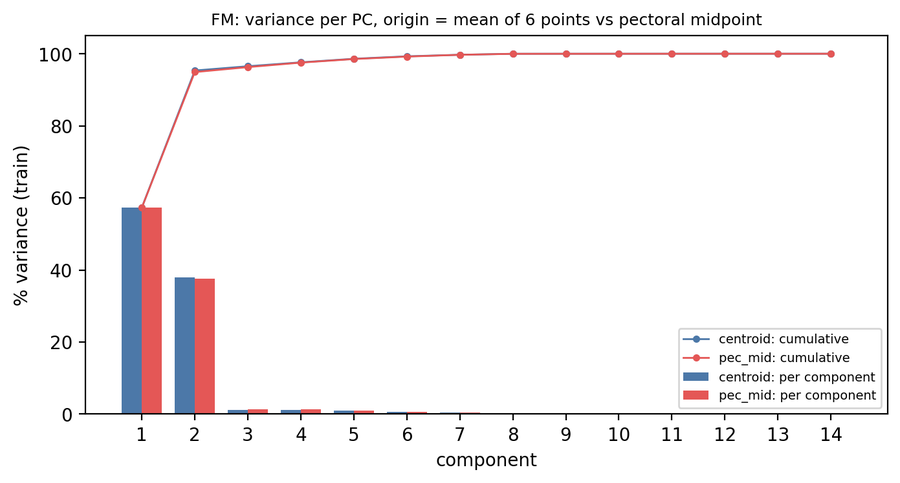

  fig figures/01_pca_corr__FM__base__train.png


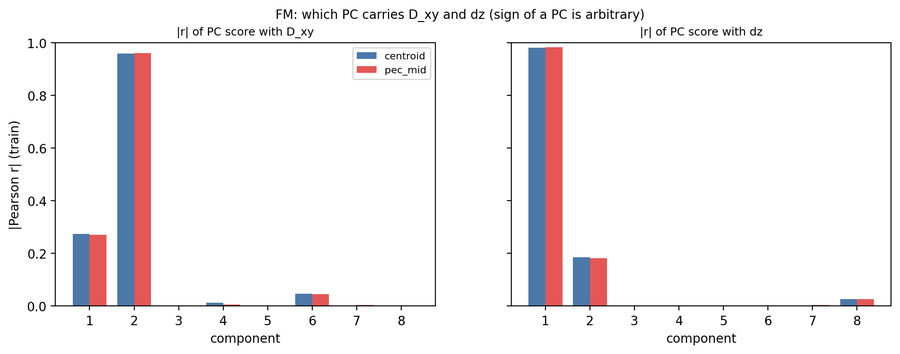

  fig figures/01_pca_loadings__FM__base__train.png
  fig figures/01_pca_variance__MM__base__train.png


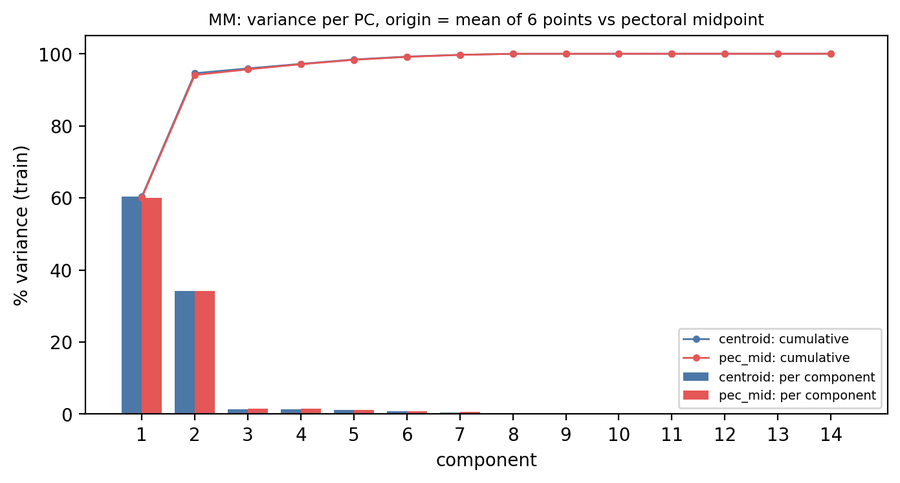

  fig figures/01_pca_corr__MM__base__train.png


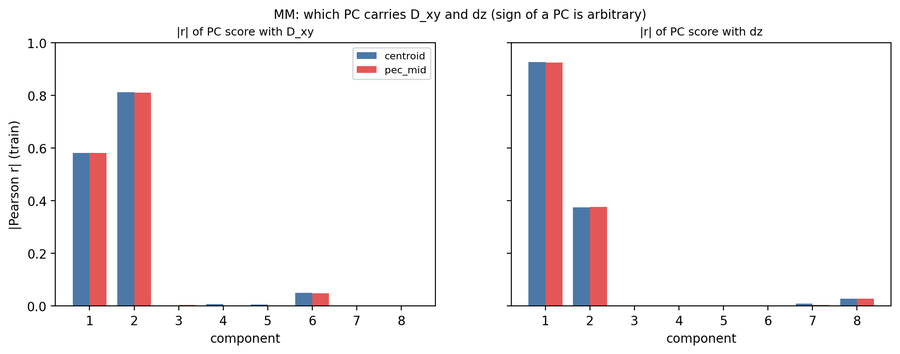

  fig figures/01_pca_loadings__MM__base__train.png
unit   origin   set  component  variance_fraction  r_D_xy   r_dz
  FM centroid train          1              0.573   0.275 -0.982
  FM centroid train          2              0.380  -0.960 -0.185
  FM centroid train          3              0.012  -0.003  0.001
  FM centroid train          4              0.011  -0.012 -0.002
  FM centroid  test          1              0.573   0.275 -0.981
  FM centroid  test          2              0.380  -0.964 -0.179
  FM centroid  test          3              0.012  -0.045  0.036
  FM centroid  test          4              0.011  -0.039 -0.080
  FM  pec_mid train          1              0.573   0.271 -0.983
  FM  pec_mid train          2              0.377  -0.961 -0.181
  FM  pec_mid train          3              0.014  -0.003  0.002
  FM  pec_mid train          4              0.012  -0.005 -0.003
  FM  pec_mid  test          1              0.573   0.272 -0.981
  FM  pec_mid  test          2         

In [4]:
# Step 1 (figures): variance, |r| with D_xy and dz, loadings; two origins side by side.
for unit in PCA_UNITS:
    fig, ax = plt.subplots(figsize=(8, 3.8))
    k = len(FEAT14)
    w = 0.38
    for i, origin in enumerate(ORIGINS):
        ev = PCA_RES[(unit, origin)]["variance_fraction"]
        x = np.arange(1, k + 1) + (i - 0.5) * w
        ax.bar(x, 100 * ev, width=w, color=ORIGIN_COLOR[origin], label=f"{origin}: per component")
        ax.plot(np.arange(1, k + 1), 100 * np.cumsum(ev), "o-", ms=3, color=ORIGIN_COLOR[origin], lw=1,
                label=f"{origin}: cumulative")
    ax.set_xticks(np.arange(1, k + 1))
    ax.set_xlabel("component")
    ax.set_ylabel("% variance (train)")
    ax.legend(fontsize=7)
    ax.set_title(f"{unit}: variance per PC, origin = mean of 6 points vs pectoral midpoint", fontsize=9)
    show(L.save_fig(fig, "01", "pca_variance", unit, "base", "train"))

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
    for ax, var, nm in ((axes[0], "abs_r_D_xy", "D_xy"), (axes[1], "abs_r_dz", "dz")):
        for i, origin in enumerate(ORIGINS):
            d = PCA_CMP[(PCA_CMP.unit == unit) & (PCA_CMP.origin == origin) & (PCA_CMP.set == "train")]
            ax.bar(d.component + (i - 0.5) * 0.38, d[var], width=0.38, color=ORIGIN_COLOR[origin], label=origin)
        ax.set_xticks(np.arange(1, PCA_SHOW + 1))
        ax.set_xlabel("component")
        ax.set_title(f"|r| of PC score with {nm}", fontsize=9)
        ax.set_ylim(0, 1)
    axes[0].set_ylabel("|Pearson r| (train)")
    axes[0].legend(fontsize=8)
    fig.suptitle(f"{unit}: which PC carries D_xy and dz (sign of a PC is arbitrary)", fontsize=10)
    show(L.save_fig(fig, "01", "pca_corr", unit, "base", "train"))

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    for ax, origin in zip(axes, ORIGINS):
        mdl = PCA_RES[(unit, origin)]
        ev = mdl["variance_fraction"]
        im = ax.imshow(mdl["eigenvectors"], cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
        ax.set_yticks(np.arange(len(FEAT14)), FEAT14, fontsize=7)
        ax.set_xticks(np.arange(len(ev)), [f"PC{i + 1}\n{100 * ev[i]:.1f}%" for i in range(len(ev))], fontsize=6)
        ax.set_title(f"origin = {origin}", fontsize=9)
    fig.colorbar(im, ax=axes, fraction=0.02, label="loading")
    fig.suptitle(f"{unit}: loadings (a = {UNITS[unit][0][0]}, b = {UNITS[unit][0][1]})", fontsize=10)
    L.save_fig(fig, "01", "pca_loadings", unit, "base", "train")

cols = ["unit", "origin", "set", "component", "variance_fraction", "r_D_xy", "r_dz"]
print(PCA_CMP[PCA_CMP.component <= 4][cols].round(3).to_string(index=False))
L.log("01", "done")

## Step 1b — PC1、PC2 是水平（XY）还是上下（Z）的变化？（仿论文 Fig. 2a）

**做什么**：每个 PC 的特征向量就是"6 个点一起怎么动"。把平均姿势加上 ±2 个标准差（`MODE_SD`）的该成分，还原成 6 个点（`M.reconstruct_pose`，两种原点各自的还原方式），从上方（x'–y'）和侧面（x'–z'）画出来。x' = 水平胸鳍→胸鳍方向，y' = 水平垂直方向，z' = 上下。

数字指标：把一个 PC 的位移分解到三个方向，`x' / y' / z' 份额` = 6 个点在该方向上的位移平方和 / 总位移平方和（三者相加 = 1）。z' 份额接近 1 = 这个 PC 是上下的变化；x' + y' 份额接近 1 = 水平的变化。

**图**：
- `01b_pca_modes__<unit>`：行 = 原点 × 视图（上方、侧面），列 = PC1、PC2。灰 = 平均姿势，蓝 = −2 SD，红 = +2 SD；实线 = 鱼 a（FM 为雌鱼），虚线 = 鱼 b；圆点 = 胸鳍，三角 = 嘴。
- `01b_pca_scatter__<unit>`：PC1、PC2 得分对 Δz、D_xy 的二维直方图（训练集，质心原点；胸鳍中点原点的 r 见 Step 1 的表）。

**输出**：`data/01b_pca_mode_axes__all__base__train.csv`（单元 × 原点 × 成分：x'/y'/z' 份额）。

  csv data/01b_pca_mode_axes__all__base__train.csv  rows 32
unit   origin  component  variance_fraction  x_share  y_share  z_share
  FM centroid          1              0.573    0.050    0.000    0.949
  FM centroid          2              0.380    0.949    0.000    0.051
  FM centroid          3              0.012    0.001    0.998    0.001
  FM centroid          4              0.011    0.982    0.012    0.007
  FM  pec_mid          1              0.573    0.049    0.000    0.951
  FM  pec_mid          2              0.377    0.951    0.000    0.049
  FM  pec_mid          3              0.014    0.001    0.999    0.001
  FM  pec_mid          4              0.012    0.992    0.002    0.006
  MM centroid          1              0.603    0.227    0.000    0.773
  MM centroid          2              0.343    0.775    0.000    0.225
  MM centroid          3              0.013    0.034    0.966    0.001
  MM centroid          4              0.013    0.630    0.366    0.004
  MM  pec_mid    

  fig figures/01b_pca_modes__FM__base__train.png


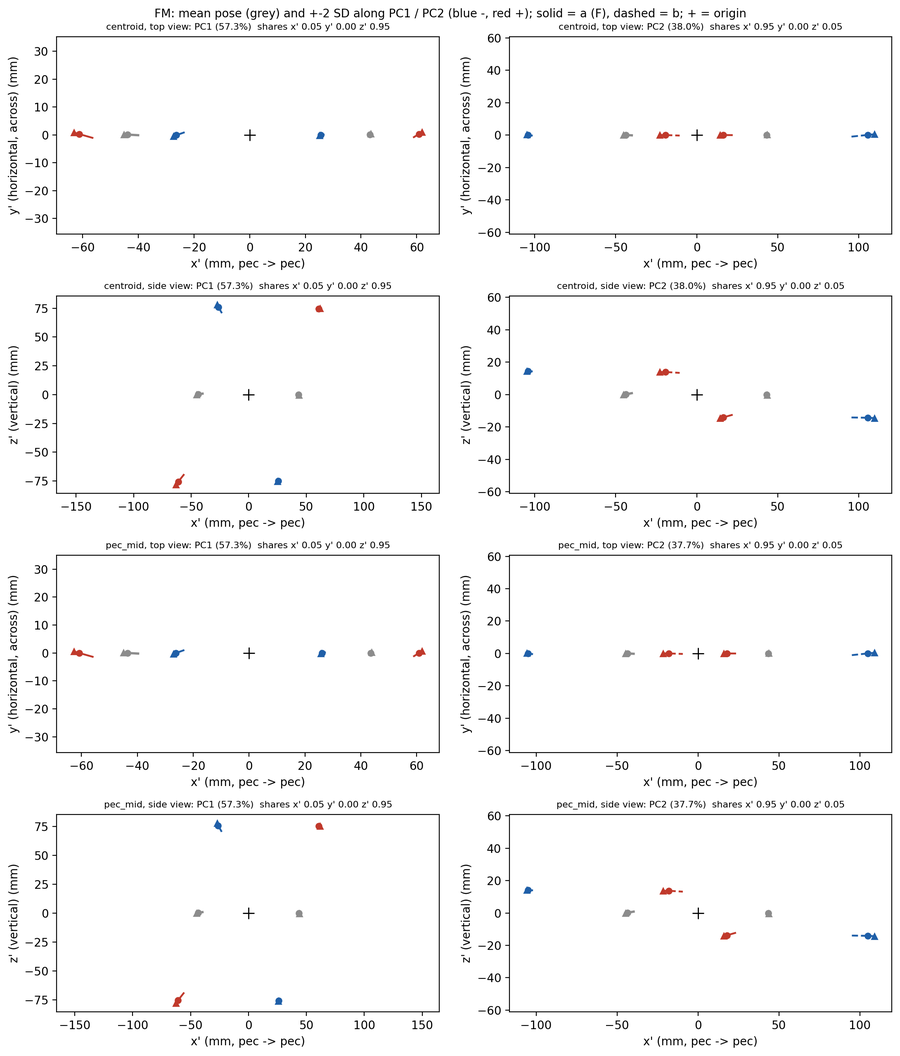

  fig figures/01b_pca_scatter__FM__base__train.png


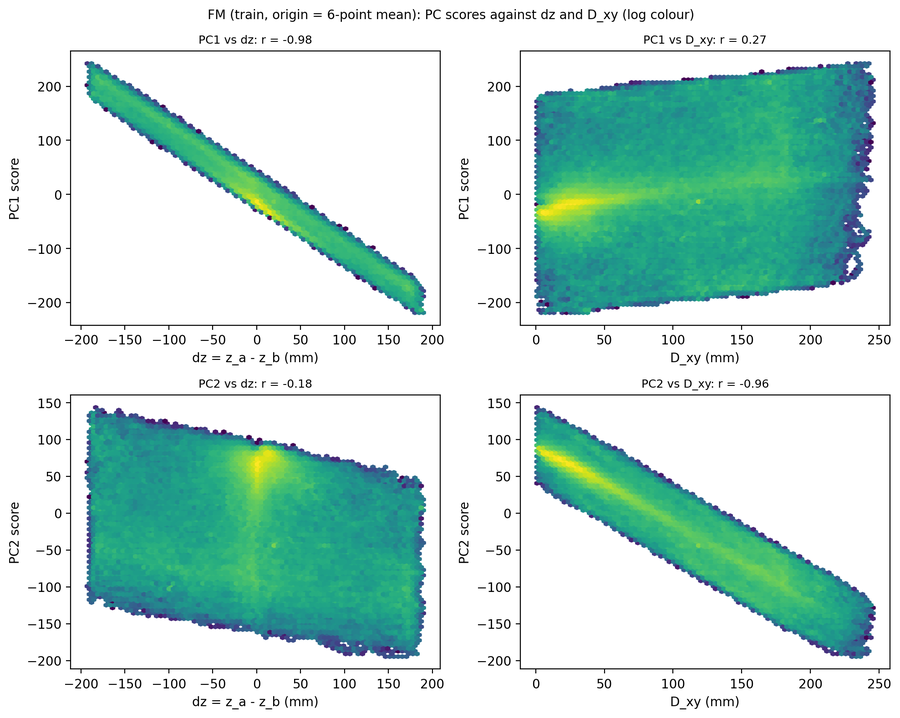

  fig figures/01b_pca_modes__MM__base__train.png


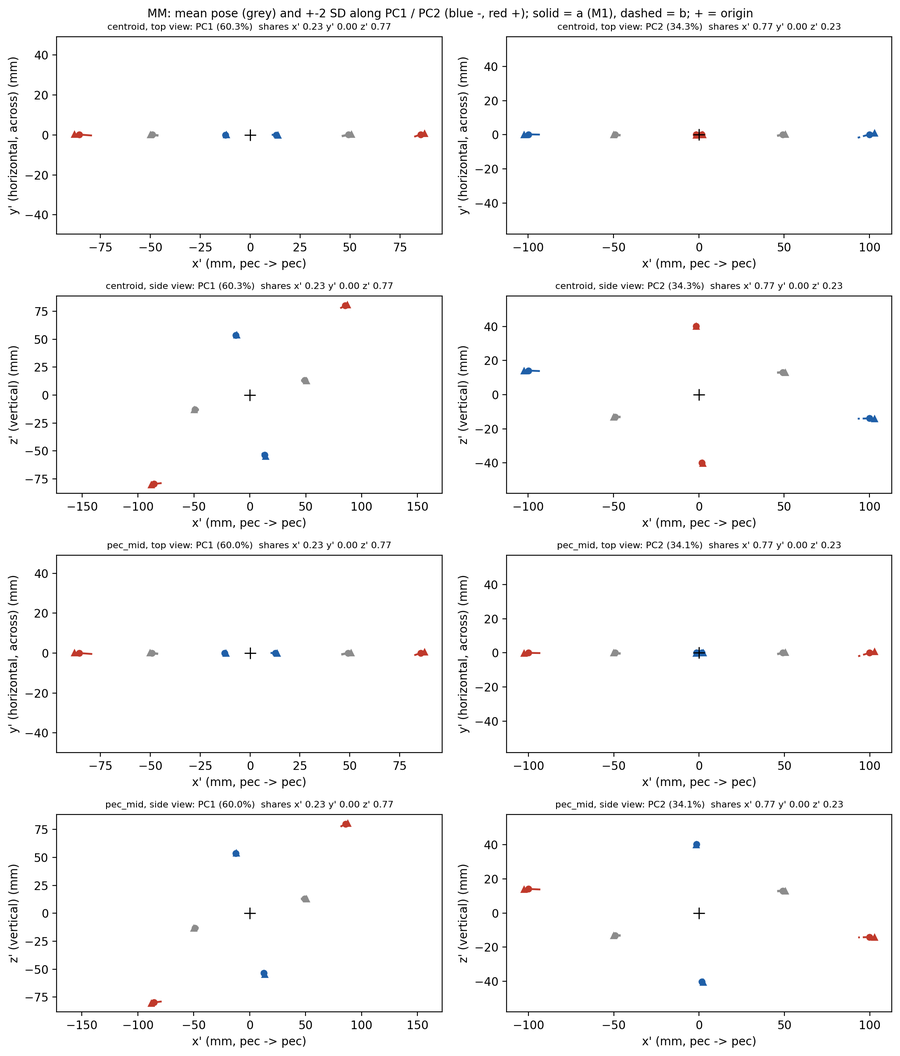

  fig figures/01b_pca_scatter__MM__base__train.png


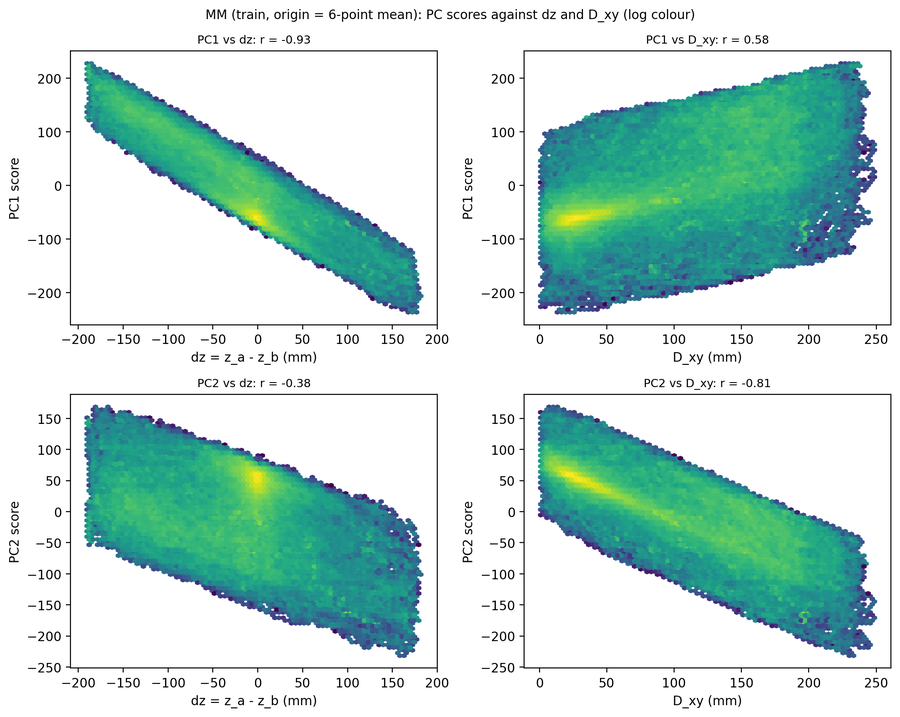

In [5]:
# Step 1b: what PC1 and PC2 look like (displacement of the six points), and their x'/y'/z' shares.
MODE_SD = 2.0
EDGES6 = [(0, 1), (1, 2), (3, 4), (4, 5)]   # mouth-pec-tail of fish a, then fish b
axis_rows = []
for unit in PCA_UNITS:
    for origin in ORIGINS:
        mdl = PCA_RES[(unit, origin)]
        for j in range(PCA_SHOW):
            d = M.reconstruct_pose(mdl["eigenvectors"][:, j], origin)   # (6, 3) displacement per unit score
            sq = (d ** 2).sum(axis=0) / (d ** 2).sum()
            axis_rows.append({"unit": unit, "origin": origin, "component": j + 1,
                              "variance_fraction": mdl["variance_fraction"][j],
                              "x_share": sq[0], "y_share": sq[1], "z_share": sq[2]})
AXES = pd.DataFrame(axis_rows)
L.save_csv(AXES, "01b", "pca_mode_axes", "all", "base", "train")
print(AXES[AXES.component <= 4].round(3).to_string(index=False))

for unit in PCA_UNITS:
    fig, axes = plt.subplots(4, 2, figsize=(11, 13))
    for oi, origin in enumerate(ORIGINS):
        mdl = PCA_RES[(unit, origin)]
        mean = M.reconstruct_pose(mdl["mean"], origin)
        for j in range(2):
            sd = np.sqrt(mdl["eigenvalues"][j])
            disp = M.reconstruct_pose(mdl["eigenvectors"][:, j], origin)
            ax_row = AXES[(AXES.unit == unit) & (AXES.origin == origin) & (AXES.component == j + 1)].iloc[0]
            for vi, (dim, vname) in enumerate(((1, "y' (horizontal, across)"), (2, "z' (vertical)"))):
                ax = axes[2 * oi + vi, j]
                for k, col in ((-MODE_SD, "#1f5fa8"), (0.0, "0.55"), (MODE_SD, "#c0392b")):
                    pose = mean + k * sd * disp
                    for e0, e1 in EDGES6:
                        ax.plot(pose[[e0, e1], 0], pose[[e0, e1], dim], color=col, lw=2 if k == 0 else 1.6,
                                ls="-" if e0 < 3 else "--")
                    ax.plot(pose[[1, 4], 0], pose[[1, 4], dim], "o", color=col, ms=5)
                    ax.plot(pose[[0, 3], 0], pose[[0, 3], dim], "^", color=col, ms=5)
                ax.plot(0, 0, "k+", ms=10)
                ax.set_aspect("equal", adjustable="datalim")
                ax.set_xlabel("x' (mm, pec -> pec)")
                ax.set_ylabel(f"{vname} (mm)")
                ax.set_title(f"{origin}, {'top' if vi == 0 else 'side'} view: PC{j + 1} "
                             f"({100 * ax_row.variance_fraction:.1f}%)  shares x' {ax_row.x_share:.2f} "
                             f"y' {ax_row.y_share:.2f} z' {ax_row.z_share:.2f}", fontsize=8)
    fig.suptitle(f"{unit}: mean pose (grey) and +-{MODE_SD:g} SD along PC1 / PC2 (blue -, red +); "
                 f"solid = a ({UNITS[unit][0][0]}), dashed = b; + = origin", fontsize=10)
    fig.tight_layout()
    show(L.save_fig(fig, "01b", "pca_modes", unit, "base", "train"))

    data = pca_inputs(unit, "train")
    sc = M.pca_scores(data[0], PCA_RES[(unit, "centroid")])
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    for j in range(2):
        for vi, (col, nm) in enumerate(((1, "dz = z_a - z_b (mm)"), (0, "D_xy (mm)"))):
            ax = axes[j, vi]
            m = np.isfinite(sc[:, j]) & np.isfinite(data[1][:, col])
            ax.hexbin(data[1][m, col], sc[m, j], gridsize=80, bins="log", cmap="viridis", mincnt=1)
            ax.set_xlabel(nm)
            ax.set_ylabel(f"PC{j + 1} score")
            ax.set_title(f"PC{j + 1} vs {nm.split(' ')[0]}: r = {pearson(sc[:, j], data[1][:, col]):.2f}", fontsize=9)
    fig.suptitle(f"{unit} (train, origin = 6-point mean): PC scores against dz and D_xy (log colour)", fontsize=10)
    fig.tight_layout()
    show(L.save_fig(fig, "01b", "pca_scatter", unit, "base", "train"))
L.log("01b", "done")

### Step 1b（续）— 放大身体：每个 PC 下每条鱼自身姿势怎么变

上一张图里两条鱼相距约 90 mm，身体（约 25 mm）太小看不清。这里把每条鱼**以它自己的胸鳍为中心**单独画出（减去该鱼胸鳍的位置），坐标范围 ±`BODY_HALF_MM`，看沿 PC1 / PC2 ±2 SD 时身体的朝向、俯仰、弯曲有没有变化。胸鳍本身怎么移动（两条鱼的相对位置）见上一张图。

**图** `01b_pca_modes_body__<unit>`：行 = 鱼 a 俯视、鱼 a 侧视、鱼 b 俯视、鱼 b 侧视；列 = PC1（质心原点）、PC1（胸鳍中点原点）、PC2（质心）、PC2（胸鳍中点）。灰 = 平均姿势，蓝 = −2 SD，红 = +2 SD；三角 = 嘴，圆点 = 胸鳍（固定在 0），方块 = 尾。

  fig figures/01b_pca_modes_body__FM__base__train.png


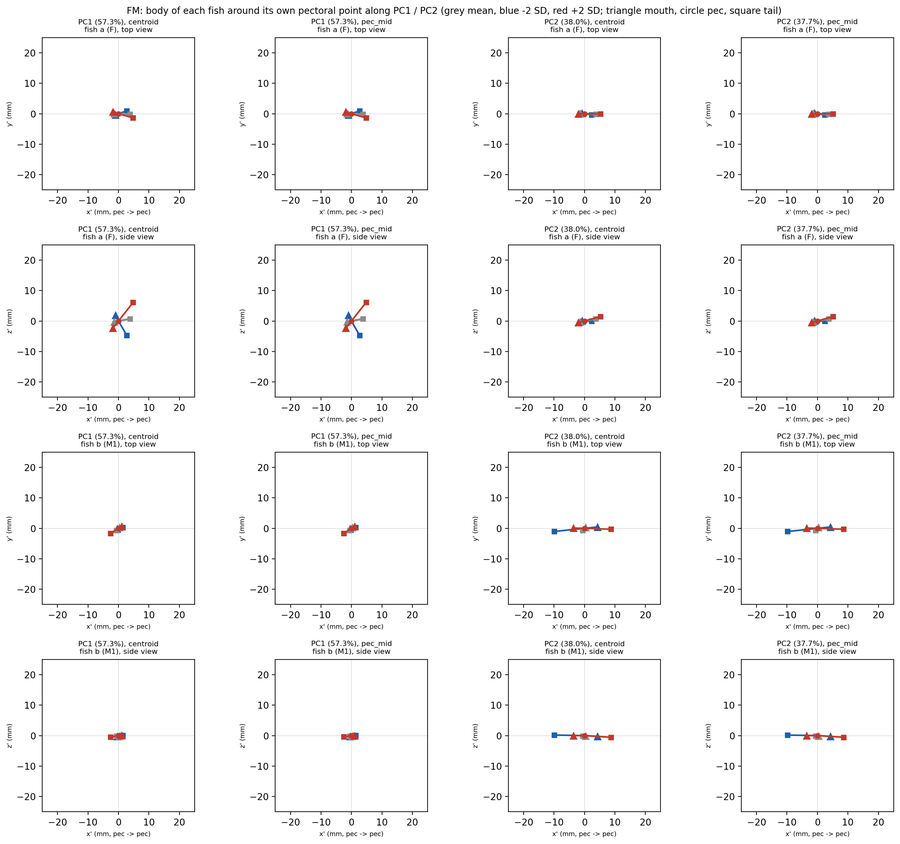

  fig figures/01b_pca_modes_body__MM__base__train.png


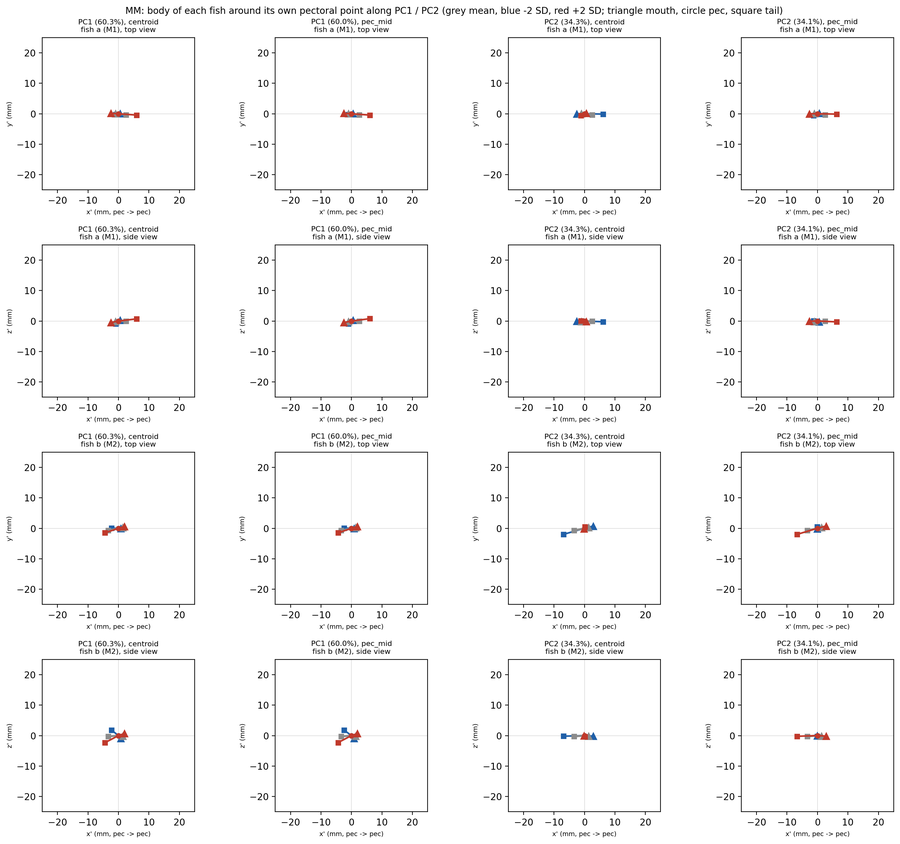

In [6]:
# Step 1b (continued): each fish drawn around its own pectoral point, so body orientation / pitch / bend are visible.
BODY_HALF_MM = 25.0
for unit in PCA_UNITS:
    cols = [(j, origin) for j in range(2) for origin in ORIGINS]
    fig, axes = plt.subplots(4, len(cols), figsize=(3.6 * len(cols), 13))
    for ci, (j, origin) in enumerate(cols):
        mdl = PCA_RES[(unit, origin)]
        mean = M.reconstruct_pose(mdl["mean"], origin)
        disp = M.reconstruct_pose(mdl["eigenvectors"][:, j], origin)
        sd = np.sqrt(mdl["eigenvalues"][j])
        for fi, (fish, idx) in enumerate((("a", [0, 1, 2]), ("b", [3, 4, 5]))):
            for vi, (dim, vname) in enumerate(((1, "y'"), (2, "z'"))):
                ax = axes[2 * fi + vi, ci]
                for k, col in ((-MODE_SD, "#1f5fa8"), (0.0, "0.55"), (MODE_SD, "#c0392b")):
                    p = (mean + k * sd * disp)[idx]
                    p = p - p[1]                                  # own pectoral point at 0
                    ax.plot(p[:, 0], p[:, dim], color=col, lw=2.2 if k == 0 else 1.8)
                    ax.plot(p[0, 0], p[0, dim], "^", color=col, ms=7)
                    ax.plot(p[1, 0], p[1, dim], "o", color=col, ms=5)
                    ax.plot(p[2, 0], p[2, dim], "s", color=col, ms=5)
                ax.set_xlim(-BODY_HALF_MM, BODY_HALF_MM)
                ax.set_ylim(-BODY_HALF_MM, BODY_HALF_MM)
                ax.set_aspect("equal")
                ax.axhline(0, color="0.85", lw=0.6, zorder=0)
                ax.axvline(0, color="0.85", lw=0.6, zorder=0)
                ax.set_xlabel("x' (mm, pec -> pec)", fontsize=7)
                ax.set_ylabel(f"{vname} (mm)", fontsize=7)
                ev = mdl["variance_fraction"][j]
                ax.set_title(f"PC{j + 1} ({100 * ev:.1f}%), {origin}\nfish {fish} "
                             f"({UNITS[unit][0][0 if fish == 'a' else 1]}), {'top' if vi == 0 else 'side'} view",
                             fontsize=8)
    fig.suptitle(f"{unit}: body of each fish around its own pectoral point along PC1 / PC2 "
                 f"(grey mean, blue -{MODE_SD:g} SD, red +{MODE_SD:g} SD; triangle mouth, circle pec, square tail)",
                 fontsize=10)
    fig.tight_layout()
    show(L.save_fig(fig, "01b", "pca_modes_body", unit, "base", "train"))

### Step 1b（续 2）— 加在实际长度直身鱼上的 PC1 / PC2

上一张图的"平均姿势"是所有帧的平均。各帧里鱼的朝向不同，平均后身体向量互相抵消，所以身体只有约 5 mm 长。这里改用一个**参照姿势**：两个胸鳍点放在平均位置，每条鱼画成实际长度的直身鱼（嘴–胸鳍、胸鳍–尾长度 = 训练集中位数），两条鱼水平、面对面（θ_a = θ_b = 0）。然后加上沿 PC1 / PC2 的 ±2 SD 位移（6 个点的位移和前面完全相同，只是加在这个参照姿势上）。箭头 = 从参照姿势到 +2 SD 的移动。

参照姿势只是为了看清身体，**不是数据里的平均姿势**。

**图** `01b_pca_modes_ref__<unit>`：行 = 原点 × 视图（俯视、侧视），列 = PC1、PC2。灰 = 参照姿势，蓝 = −2 SD，红 = +2 SD；实线 = 鱼 a，虚线 = 鱼 b；三角 = 嘴，圆点 = 胸鳍，方块 = 尾；+ = 原点。

[FM] reference body: mouth-pec 6.9 mm, pec-tail 17.7 mm (train medians)


  fig figures/01b_pca_modes_ref__FM__base__train.png


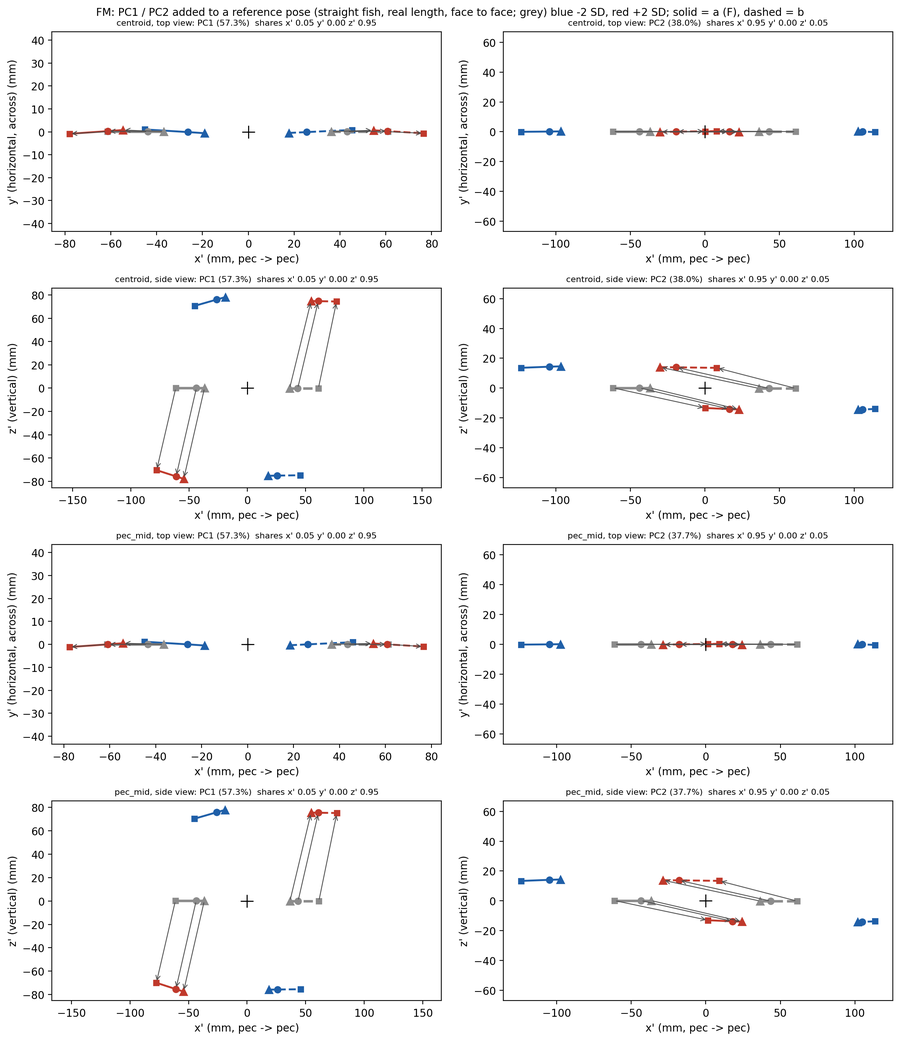

[MM] reference body: mouth-pec 7.0 mm, pec-tail 18.2 mm (train medians)


  fig figures/01b_pca_modes_ref__MM__base__train.png


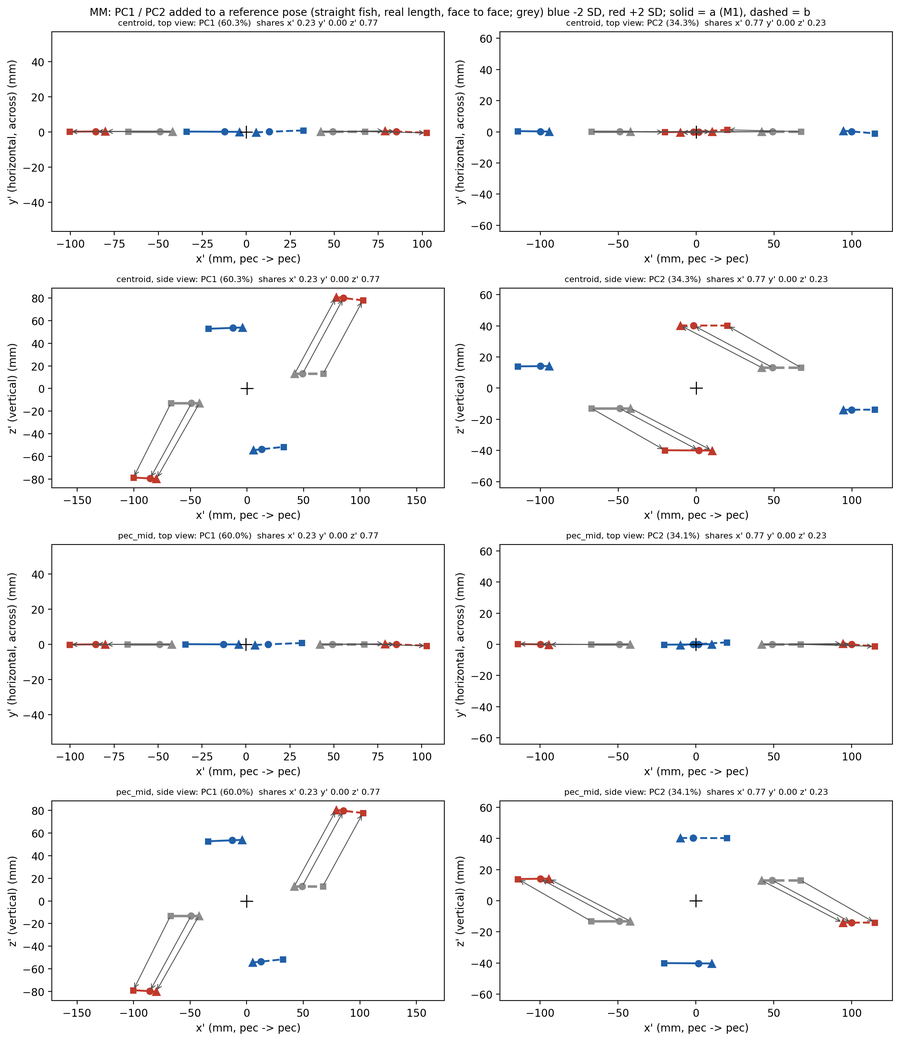

In [7]:
# Step 1b (continued 2): PC displacements added to a reference pose with real body lengths.
for unit in PCA_UNITS:
    X, _P = pca_inputs(unit, "train")
    ok = np.isfinite(X).all(axis=1)
    pz = M.reconstruct_pose(X[ok][::10])
    hp = float(np.median(np.linalg.norm(np.concatenate([pz[:, 0] - pz[:, 1], pz[:, 3] - pz[:, 4]]), axis=1)))
    pt = float(np.median(np.linalg.norm(np.concatenate([pz[:, 2] - pz[:, 1], pz[:, 5] - pz[:, 4]]), axis=1)))
    print(f"[{unit}] reference body: mouth-pec {hp:.1f} mm, pec-tail {pt:.1f} mm (train medians)")
    fig, axes = plt.subplots(4, 2, figsize=(12, 14))
    for oi, origin in enumerate(ORIGINS):
        mdl = PCA_RES[(unit, origin)]
        mean = M.reconstruct_pose(mdl["mean"], origin)
        pa, pb = mean[1].copy(), mean[4].copy()
        ex = np.array([1.0, 0.0, 0.0])
        ref = np.stack([pa + hp * ex, pa, pa - pt * ex, pb - hp * ex, pb, pb + pt * ex])   # face to face
        for j in range(2):
            sd = np.sqrt(mdl["eigenvalues"][j])
            disp = M.reconstruct_pose(mdl["eigenvectors"][:, j], origin)
            ax_row = AXES[(AXES.unit == unit) & (AXES.origin == origin) & (AXES.component == j + 1)].iloc[0]
            for vi, (dim, vname) in enumerate(((1, "y' (horizontal, across)"), (2, "z' (vertical)"))):
                ax = axes[2 * oi + vi, j]
                for k, col in ((-MODE_SD, "#1f5fa8"), (0.0, "0.55"), (MODE_SD, "#c0392b")):
                    pose = ref + k * sd * disp
                    for f0, ls in ((0, "-"), (3, "--")):
                        ax.plot(pose[f0:f0 + 3, 0], pose[f0:f0 + 3, dim], color=col, ls=ls, lw=2.4 if k == 0 else 1.8)
                        ax.plot(pose[f0, 0], pose[f0, dim], "^", color=col, ms=7)
                        ax.plot(pose[f0 + 1, 0], pose[f0 + 1, dim], "o", color=col, ms=6)
                        ax.plot(pose[f0 + 2, 0], pose[f0 + 2, dim], "s", color=col, ms=5)
                tip = ref + MODE_SD * sd * disp
                for p0, p1 in zip(ref, tip):
                    ax.annotate("", xy=(p1[0], p1[dim]), xytext=(p0[0], p0[dim]),
                                arrowprops=dict(arrowstyle="->", color="0.3", lw=0.8))
                ax.plot(0, 0, "k+", ms=12)
                ax.set_aspect("equal", adjustable="datalim")
                ax.set_xlabel("x' (mm, pec -> pec)")
                ax.set_ylabel(f"{vname} (mm)")
                ax.set_title(f"{origin}, {'top' if vi == 0 else 'side'} view: PC{j + 1} "
                             f"({100 * ax_row.variance_fraction:.1f}%)  shares x' {ax_row.x_share:.2f} "
                             f"y' {ax_row.y_share:.2f} z' {ax_row.z_share:.2f}", fontsize=8)
    fig.suptitle(f"{unit}: PC1 / PC2 added to a reference pose (straight fish, real length, face to face; grey) "
                 f"blue -{MODE_SD:g} SD, red +{MODE_SD:g} SD; solid = a ({UNITS[unit][0][0]}), dashed = b",
                 fontsize=10)
    fig.tight_layout()
    show(L.save_fig(fig, "01b", "pca_modes_ref", unit, "base", "train"))

## Step 1c — 为什么换原点几乎没有影响

**推导**：两种原点每帧只差一个平移向量，6 个点减去同一个向量
c = 质心 − 胸鳍中点 = [(嘴_a − 胸鳍_a) + (尾_a − 胸鳍_a) + (嘴_b − 胸鳍_b) + (尾_b − 胸鳍_b)] / 6，
也就是两条鱼"胸鳍→嘴"和"胸鳍→尾"四个身体向量之和的 1/6。它只和每条鱼自己的身体朝向、弯曲有关，和两条鱼之间相隔多远、谁高谁低无关。而 PC1、PC2 描述的正是两条鱼的相对位置（胸鳍→胸鳍向量，即 D_xy 和 Δz），这个向量减去任何原点都不变。所以：(1) c 很小（嘴在前、尾在后，同一条鱼的两个向量方向大致相反，部分抵消）；(2) c 的变化主要随朝向变化，落在 PC3 以后的小成分里。

**做什么**：在训练集上算每帧的 c（转正后的坐标），报告它的大小、各方向的标准差，并和 D_xy、Δz 的标准差、两种原点下 14 个坐标的总方差对比。

**输出**：`data/01c_origin_shift__all__base__train.csv`。

In [8]:
# Step 1c: size of the shift between the two origins compared with the pair geometry.
shift_rows = []
for unit in PCA_UNITS:
    X, P = pca_inputs(unit, "train")
    ok = np.isfinite(X).all(axis=1)
    pose = M.reconstruct_pose(X[ok])                 # centroid origin
    c = 0.5 * (pose[:, 1] + pose[:, 4])              # pectoral midpoint in centroid coordinates = minus the shift
    mag = np.linalg.norm(c, axis=1)
    tot = {o: float(np.nanvar(X[ok] if o == "centroid" else M.recentre_pec_mid(X[ok]), axis=0).sum()) for o in ORIGINS}
    shift_rows.append({"unit": unit, "frames": int(ok.sum()),
                       "shift_median_mm": float(np.median(mag)), "shift_p95_mm": float(np.percentile(mag, 95)),
                       "shift_sd_x_mm": float(c[:, 0].std()), "shift_sd_y_mm": float(c[:, 1].std()),
                       "shift_sd_z_mm": float(c[:, 2].std()),
                       "D_xy_sd_mm": float(np.nanstd(P[ok, 0])), "dz_sd_mm": float(np.nanstd(P[ok, 1])),
                       "total_variance_centroid_mm2": tot["centroid"], "total_variance_pec_mid_mm2": tot["pec_mid"]})
SHIFT = pd.DataFrame(shift_rows)
L.save_csv(SHIFT, "01c", "origin_shift", "all", "base", "train")
print(SHIFT.round(2).T.to_string(header=False))
L.log("01c", "done")

  csv data/01c_origin_shift__all__base__train.csv  rows 2
unit                               FM        MM
frames                        2632407   1318615
shift_median_mm                   2.9      2.91
shift_p95_mm                     3.79      3.86
shift_sd_x_mm                    1.81       1.8
shift_sd_y_mm                     1.8      1.87
shift_sd_z_mm                    1.13      1.13
D_xy_sd_mm                      63.88     62.55
dz_sd_mm                        76.75     72.01
total_variance_centroid_mm2  12803.27  11801.15
total_variance_pec_mid_mm2   12849.96  11863.27


## Step 1d — 检查：原点真的换了吗？结果为什么几乎一样？

两种原点的结果几乎相同，所以要排除"计算没生效"或"读了旧文件"的可能。三项检查：

1. **从原始轨迹重算**（`CHECK_EXPERIMENT`，FM1 配对）：重新读审核后的原始 3D 坐标，按 v3b 参数（`params.json`）重做清洗（去异常骨架 → ≤ 5 帧插值 → SG 平滑），然后：
   - (a) 用 `align_pair(origin="centroid")` 算质心坐标，和 v3b 文件里的 `pca_FM1` 比较，应当相同（证明读的文件就是这些数据）；
   - (b) 用 `align_pair(origin="pec_mid")` **直接**算胸鳍中点坐标，和本 notebook 用的"读文件后换原点"（`recentre_pec_mid`）比较，应当相同（证明换原点的计算正确）；
   - (c) 两种原点下同一帧坐标的差：应当不为 0，约几 mm（证明原点确实换了）；
   - (d) 胸鳍中点到原点的距离：胸鳍中点原点下应当为 0，质心原点下不为 0。
2. **PCA 本身的差别**：两种原点的 PCA 均值（平均姿势）差多少；PC1、PC2 特征向量的夹角（0° = 完全相同）。
3. **阳性对照**：原点换成一个差别很大的位置，即鱼 a 自己的胸鳍点（偏移 = 半个胸鳍间距，几十 mm，而且随两鱼距离变化）。如果流程会随原点变化，这里的载荷和贡献率应当明显不同。

**图** `01d_loadings_three_origins__<unit>`：三种原点（6 点平均、胸鳍中点、鱼 a 胸鳍）的载荷热图并排。

**输出**：`data/01d_check__all__base__all.csv`、`data/01d_three_origins__all__base__train.csv`。

C:\Users\ReiterU\Documents\GitHub\medaka-mating-pipeline\scripts\analysis\microstate.py:569: RuntimeWarning: Mean of empty slice
  centre = np.nanmean(masked, axis=1)


20251225_K_1_1_FCMC FM1, recomputed from the raw tracks:
                                                                   check         value
             (a) recomputed centroid coords vs v3b file: max |diff| (mm)      0.000004
(b) direct pec_mid coords vs recentre_pec_mid(v3b file): max |diff| (mm)      0.000011
             (c) pec_mid - centroid, same frame: RMS over 14 coords (mm)      1.504713
        (c) pec_mid - centroid, same frame: median |diff| per coord (mm)      0.995054
                     (c) pec_mid - centroid, same frame: max |diff| (mm)      4.796828
    (d) centroid origin: median distance pectoral midpoint - origin (mm)      2.690426
        (d) pec_mid origin: max distance pectoral midpoint - origin (mm)      0.000000
                                                         frames compared 334879.000000

example frame, first 6 coordinates (a_mouth x' y' z', a_tail x' y' z'):
  centroid: [-17.49   3.65   8.58   4.79  -4.07   1.22]
  pec_mid:  [-13.17   2.95   8.

  csv data/01d_three_origins__all__base__train.csv  rows 12

Three origins (train):
unit          origin  component  variance_percent  abs_r_D_xy  abs_r_dz  angle_to_centroid_PC_deg  mean_pose_diff_to_centroid_mm
  FM        centroid          1            57.311       0.275     0.982                     0.000                          0.000
  FM        centroid          2            38.027       0.960     0.185                     0.000                          0.000
  FM         pec_mid          1            57.255       0.271     0.983                     0.461                          0.339
  FM         pec_mid          2            37.658       0.961     0.181                     0.936                          0.339
  FM a_pec (control)          1            59.434       0.268     0.984                    39.553                         43.822
  FM a_pec (control)          2            38.411       0.963     0.178                    39.230                         43.822
  MM        c

  fig figures/01d_loadings_three_origins__FM__base__train.png


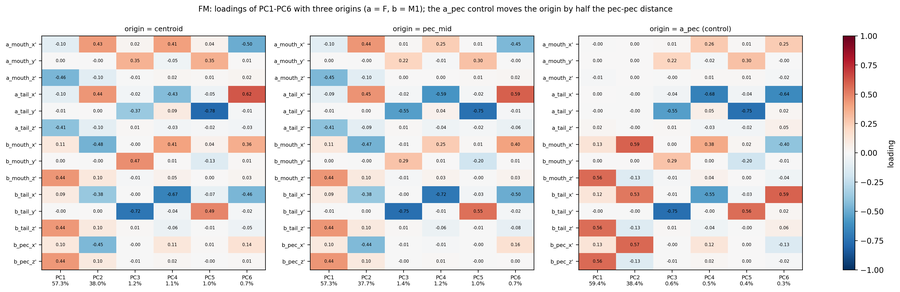

  fig figures/01d_loadings_three_origins__MM__base__train.png


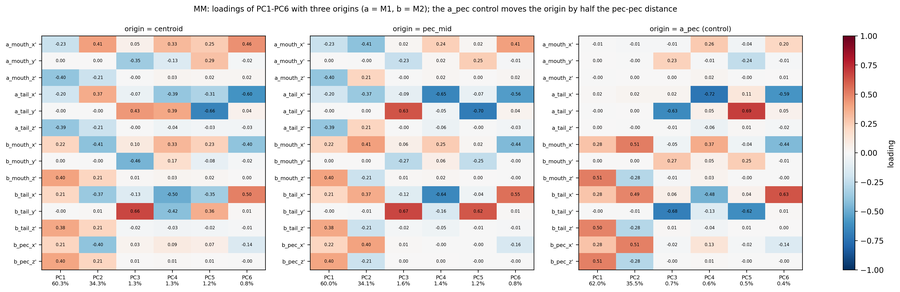

In [9]:
# Step 1d: independent recomputation from the raw tracks, and a positive control with a far-off origin.
CHECK_EXPERIMENT = TRAIN_EXPERIMENTS[0]
CHECK_COPY = "FM1"
V3B = json.loads((SRC.parent / "params.json").read_text())["parameters"]
tr = M.load_trial(CHECK_EXPERIMENT, final=True)
nodes = np.array(tr["named"], dtype=np.float64, copy=True)
blocked = np.asarray(tr["blocked"], dtype=bool)
hp = np.linalg.norm(nodes[:, :, P4.HEAD] - nodes[:, :, P4.PEC], axis=-1)
ptl = np.linalg.norm(nodes[:, :, P4.PEC] - nodes[:, :, P4.TAIL], axis=-1)
bad = (np.isfinite(hp) & (hp > V3B["HEAD_PEC_MAX_MM"])) | (np.isfinite(ptl) & (ptl > V3B["PEC_TAIL_MAX_MM"]))
nodes[bad] = np.nan
nodes = M.fill_gaps(nodes, V3B["FILL_LIMIT"], blocked)
nodes = P4.smooth_tracks(nodes, V3B["SMOOTH_WINDOW"], V3B["SG_ORDER"])
a, b = COPY_PAIR[CHECK_COPY]
pts = M.pair_points(nodes, f"{a}-{b}")
direct_c, valid = M.align_pair(pts, V3B["MIN_XY_MM"], origin="centroid")
direct_p, _ = M.align_pair(pts, V3B["MIN_XY_MM"], origin="pec_mid")
saved = PV[CHECK_EXPERIMENT][f"pca_{CHECK_COPY}"].astype(np.float64)
ok = valid & np.isfinite(saved).all(axis=1)
shifted = M.recentre_pec_mid(saved[ok])
diff = direct_p[ok] - direct_c[ok]
pose_c = M.reconstruct_pose(direct_c[ok], "centroid")
pose_p = M.reconstruct_pose(direct_p[ok], "pec_mid")
check = pd.DataFrame([
    {"check": "(a) recomputed centroid coords vs v3b file: max |diff| (mm)", "value": float(np.abs(direct_c[ok] - saved[ok]).max())},
    {"check": "(b) direct pec_mid coords vs recentre_pec_mid(v3b file): max |diff| (mm)", "value": float(np.abs(direct_p[ok] - shifted).max())},
    {"check": "(c) pec_mid - centroid, same frame: RMS over 14 coords (mm)", "value": float(np.sqrt((diff ** 2).mean()))},
    {"check": "(c) pec_mid - centroid, same frame: median |diff| per coord (mm)", "value": float(np.median(np.abs(diff)))},
    {"check": "(c) pec_mid - centroid, same frame: max |diff| (mm)", "value": float(np.abs(diff).max())},
    {"check": "(d) centroid origin: median distance pectoral midpoint - origin (mm)", "value": float(np.median(np.linalg.norm(0.5 * (pose_c[:, 1] + pose_c[:, 4]), axis=1)))},
    {"check": "(d) pec_mid origin: max distance pectoral midpoint - origin (mm)", "value": float(np.abs(0.5 * (pose_p[:, 1] + pose_p[:, 4])).max())},
    {"check": "frames compared", "value": int(ok.sum())},
])
print(f"{CHECK_EXPERIMENT} {CHECK_COPY}, recomputed from the raw tracks:")
print(check.to_string(index=False))
print("\nexample frame, first 6 coordinates (a_mouth x' y' z', a_tail x' y' z'):")
i0 = int(np.flatnonzero(ok)[len(np.flatnonzero(ok)) // 2])
print("  centroid:", np.round(direct_c[i0, :6], 2))
print("  pec_mid: ", np.round(direct_p[i0, :6], 2))
L.save_csv(check, "01d", "check", "all", "base", "all")


def recentre_a_pec(feat):
    # positive control: origin = fish a's pectoral point
    pose = M.reconstruct_pose(feat)
    pose = pose - pose[..., 1:2, :]
    ma, _pa, ta, mb, pb, tb = (pose[..., i, :] for i in range(6))
    return np.concatenate([ma, ta, mb, tb, pb[..., :1], pb[..., 2:3]], axis=-1)


ORIGINS3 = {"centroid": lambda x: x, "pec_mid": M.recentre_pec_mid, "a_pec (control)": recentre_a_pec}
rows3, MODELS3 = [], {}
for unit in PCA_UNITS:
    X, P = pca_inputs(unit, "train")
    for name, fn in ORIGINS3.items():
        mdl = M.pca_fit(fn(X))
        MODELS3[(unit, name)] = mdl
        sc = M.pca_scores(fn(X), mdl)
        for j in range(2):
            rows3.append({"unit": unit, "origin": name, "component": j + 1,
                          "variance_percent": 100 * mdl["variance_fraction"][j],
                          "abs_r_D_xy": abs(pearson(sc[:, j], P[:, 0])), "abs_r_dz": abs(pearson(sc[:, j], P[:, 1])),
                          "angle_to_centroid_PC_deg": float(np.degrees(np.arccos(min(1.0, abs(
                              mdl["eigenvectors"][:, j] @ MODELS3[(unit, "centroid")]["eigenvectors"][:, j]))))),
                          "mean_pose_diff_to_centroid_mm": float(np.abs(mdl["mean"] - MODELS3[(unit, "centroid")]["mean"]).max())})
THREE = pd.DataFrame(rows3)
L.save_csv(THREE, "01d", "three_origins", "all", "base", "train")
print("\nThree origins (train):")
print(THREE.round(3).to_string(index=False))

for unit in PCA_UNITS:
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
    for ax, name in zip(axes, ORIGINS3):
        mdl = MODELS3[(unit, name)]
        ev = mdl["variance_fraction"]
        im = ax.imshow(mdl["eigenvectors"][:, :6], cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
        ax.set_yticks(np.arange(len(FEAT14)), FEAT14, fontsize=7)
        ax.set_xticks(np.arange(6), [f"PC{i + 1}\n{100 * ev[i]:.1f}%" for i in range(6)], fontsize=7)
        for (r_, c_), v in np.ndenumerate(mdl["eigenvectors"][:, :6]):
            ax.text(c_, r_, f"{v:.2f}", ha="center", va="center", fontsize=5.5)
        ax.set_title(f"origin = {name}", fontsize=9)
    fig.colorbar(im, ax=axes, fraction=0.015, label="loading")
    fig.suptitle(f"{unit}: loadings of PC1-PC6 with three origins (a = {UNITS[unit][0][0]}, b = {UNITS[unit][0][1]}); "
                 f"the a_pec control moves the origin by half the pec-pec distance", fontsize=10)
    show(L.save_fig(fig, "01d", "loadings_three_origins", unit, "base", "train"))
L.log("01d", "done")

## Step 2 — 检测流程（公共函数）

qc（Step 2a，FM）和 att（Step 3，MM）用同一套代码。

**做什么**：
1. 读 v3b 的微状态（`02_microstates__<unit>`，训练、测试）。BORIS 标签同 v3b Step 2b。
2. 三种打分单位：A = 3D 胸鳍距离 2 mm 格子（0–300 mm，最后一格开放）；B = 微状态编号（16129 个，含 contact 状态）；C = 微状态所属的 Infomap 簇（测试帧投到训练集的簇）。三种方法中，没有状态的帧都归入一个单独的单位。
3. 同一流程：训练集上每个单位的分数 = P(类别 | 单位)，向训练集整体比例收缩 `PRIOR_FRAMES` 个伪帧 → 配对内居中平滑（qc 124 帧 = 0.75 s，att 5 帧，同 v3b）→ 阈值 = 训练集上 F1 最大的值 → 测试固定。
4. **C 的 τ**：主结果 = `TARGETS[...]["tau"]`（v3b 训练集选出的：qc 25、att 7）。`taus_extra` 作参照：v3b 保存过的直接读，没保存的用和 v3b Step 3 相同的设置重新跑 Infomap（训练集转移矩阵、保留自环、全部出现过的状态、行归一化、igraph Infomap `N_TRIALS` = 200 次、同一随机种子）。参照 τ 不是在训练集上为该类别选出的，只作参考。
5. **对照 v3b**：A 和 v3b 保存过的 τ 的 C，合并两个测试视频、全部配对副本的结果必须和 v3b `05_detection` 一致。

**每个测试视频的指标**（只算 `eval_copies`：FM 是 FM1 + FM2；MM 只算 M1M2，因为 M2M1 是同一对鱼的另一个顺序，重复算会把每个 bout 数两次）：
- **AP（平均精确率）**：不定阈值，把所有帧按分数从高到低排，衡量"分数越高的帧越可能是该行为"；= 精确率–召回率曲线下的面积。0–1，越大越好；随机打分 ≈ 正例帧比例。
- **帧精确率**：在训练集阈值下被判为该行为的帧中，BORIS 也是该行为的比例。越大越好。
- **帧召回率**：BORIS 该行为的帧中被判出来的比例。越大越好。
- **检出 bout / 标注 bout**：一个 bout 至少一半帧超过阈值算检出。越多越好。
- **误报区间 / 分钟**：连续超过阈值的一段，碰到有标注的帧但一帧该行为都没有 = 一个误报区间；除以配对·分钟。越小越好。
- B→C 的 bout 变化：B 检出但 C 漏掉、C 检出但 B 漏掉的 bout 数。

In [10]:
# Step 2 (setup): shared code for A / B / C, used for qc (Step 2a) and att (Step 3).
from concurrent.futures import ProcessPoolExecutor
from scipy import sparse
EDGES_JSON = json.loads(src_file("02_bin_edges__all__*__train.json").read_text())
N_STATES = int(EDGES_JSON["n_states"])
BOUTS = {e: M.bouts_of(e) for e in ALL_EXPERIMENTS + list(EXTRA_TEST_EXPERIMENTS)}
FPS_OF = {e: float(PV[e]["fps"]) for e in ALL_EXPERIMENTS}
EXTRA_MIC = {}   # unit -> microstate table of the extra test videos (filled in Step 2-extra)
DIST_EDGES = np.arange(0.0, DIST_MAX_MM + DIST_BIN_MM, DIST_BIN_MM)
MIC_CACHE = {}


def load_mic(unit):
    if unit not in MIC_CACHE:
        mic = {sn: load_npz(src_file(f"02_microstates__{unit}__*__{sn}.npz")) for sn in SETS}
        if unit in EXTRA_MIC:   # append the extra test videos after the v3b test videos
            te, ex = mic["test"], EXTRA_MIC[unit]
            n_old = len(te["exp_names"])
            seg_off = int(te["seg"].max()) + 1
            merged = {k: np.concatenate([te[k], ex[k]]) for k in ("state", "frame", "vals", "contact", "d3", "copy")}
            merged["exp"] = np.concatenate([te["exp"], ex["exp"] + n_old]).astype(te["exp"].dtype)
            merged["seg"] = np.concatenate([te["seg"], np.where(ex["seg"] >= 0, ex["seg"] + seg_off, -1)])
            merged["exp_names"] = np.concatenate([te["exp_names"], ex["exp_names"]])
            merged["copy_names"] = te["copy_names"]
            assert list(ex["copy_names"]) == list(te["copy_names"])
            mic["test"] = merged
        MIC_CACHE[unit] = mic
    return MIC_CACHE[unit]


def graph_input(counts):
    # As v3b: all occupied states, self-loops kept, row-normalised.
    c = sparse.csr_matrix(counts, dtype=np.float64)
    occ = (np.asarray(c.sum(axis=1)).ravel() > 0) | (np.asarray(c.sum(axis=0)).ravel() > 0)
    keep = np.flatnonzero(occ)
    sub = c[keep][:, keep].tolil()
    if not KEEP_SELF_LOOPS:
        sub.setdiag(0)
    sub = sub.tocsr()
    sub.eliminate_zeros()
    return keep, S.row_normalize(sub)


def cluster_labels(unit, taus, mic_train, step):
    # state -> cluster per tau: v3b files where they exist, otherwise Infomap on the training microstates
    out, jobs = {}, []
    st = mic_train["state"].astype(np.int64)
    for tau in taus:
        hits = sorted(SRC.glob(f"03_state_clusters__{unit}__tau{tau}-*__train.csv"))
        if hits:
            out[tau] = pd.read_csv(hits[0]).sort_values("state")["cluster"].to_numpy(np.int64)
            print(f"[{unit}] tau {tau}: clusters from v3b ({hits[0].name})")
        else:
            counts, n_pairs = S.transition_counts(st, mic_train["seg"], int(tau), N_STATES)
            keep, prob = graph_input(counts)
            jobs.append((tau, keep, prob))
            print(f"[{unit}] tau {tau}: Infomap on {len(keep)} states, {prob.nnz} edges, {n_pairs} transitions")
    if jobs:
        backend = S.resolve_infomap_backend()["backend"]
        t0 = time.time()
        with ProcessPoolExecutor(max_workers=INFOMAP_WORKERS) as ex:
            fut = {tau: ex.submit(S.run_infomap, prob, N_TRIALS, INFOMAP_SEED, backend) for tau, _k, prob in jobs}
            res = {tau: f.result() for tau, f in fut.items()}
        print(f"[{unit}] {len(jobs)} Infomap runs x {N_TRIALS} trials: {time.time() - t0:.0f} s")
        sf = np.bincount(st[st >= 0], minlength=N_STATES).astype(float)
        for tau, keep, _p in jobs:
            raw = np.asarray(res[tau][0], dtype=np.int64)
            k = int(raw.max()) + 1
            cover = np.bincount(raw, weights=sf[keep], minlength=k)
            order = np.lexsort((np.arange(k), -cover))   # C0 = most frames, as in v3b
            new = np.empty(k, dtype=np.int64)
            new[order] = np.arange(k)
            lab = np.full(N_STATES, -1, dtype=np.int64)
            lab[keep] = new[raw]
            out[tau] = lab
            L.save_csv(pd.DataFrame({"state": np.arange(N_STATES), "cluster": lab, "n_frames": sf.astype(int)}),
                       step, "state_clusters", unit, {"tau": tau}, "train", verbose=False)
    for tau in taus:
        assert len(out[tau]) == N_STATES
        print(f"[{unit}] tau {tau}: {int(out[tau].max()) + 1} clusters")
    return out


def labels_for(mic):
    out = np.empty(len(mic["state"]), dtype=object)
    for ei, e in enumerate([str(x) for x in mic["exp_names"]]):
        for ci, cp in enumerate([str(x) for x in mic["copy_names"]]):
            m = (mic["exp"] == ei) & (mic["copy"] == ci)
            a, b = COPY_PAIR[cp]
            out[m] = P4.pair_frame_labels(BOUTS[e], a, b, mic["frame"][m], LABEL_CLASSES, directed=True)
    return out


def blocks_of(mic):
    return mic["exp"].astype(np.int64) * 10 + mic["copy"].astype(np.int64)


def ids_A(mic):
    nb = len(DIST_EDGES)
    d = mic["d3"].astype(np.float64)
    ids = np.clip(np.searchsorted(DIST_EDGES, np.nan_to_num(d, nan=0.0), side="right") - 1, 0, nb - 1)
    return np.where((mic["state"] >= 0) & np.isfinite(d), ids, nb).astype(np.int64), nb + 1


def ids_B(mic):
    st = mic["state"].astype(np.int64)
    return np.where(st >= 0, st, N_STATES), N_STATES + 1


def make_ids_C(lab):
    def ids_C(mic):
        st = mic["state"].astype(np.int64)
        k = int(lab.max()) + 1
        cl = np.where(st >= 0, lab[np.clip(st, 0, None)], -1)
        return P4.with_nostate_cluster(cl, st >= 0, k), k + 1
    return ids_C


def bout_list(y, pred, block):
    # (start, end, found) of every run of y == 1 inside one block; found = at least half of its frames predicted
    brk = np.ones(len(y), dtype=bool)
    brk[1:] = (y[1:] != y[:-1]) | (block[1:] != block[:-1])
    starts = np.flatnonzero(brk)
    ends = np.concatenate([starts[1:], [len(y)]])
    return [(int(a), int(b), bool(np.mean(pred[a:b]) >= 0.5)) for a, b in zip(starts, ends) if y[a] == 1]


def run_target(target):
    # Fit A, B and C at every tau on train; metrics per test video (eval copies) and pooled (all copies, v3b check).
    cfg = TARGETS[target]
    unit, step, main = cfg["unit"], cfg["step"], cfg["tau"]
    taus = sorted(set([main] + list(cfg["taus_extra"])))
    ckey = lambda t: "C" if t == main else f"C_tau{t}"
    mic = load_mic(unit)
    lab_c = cluster_labels(unit, taus, mic["train"], step)
    methods = {"A": ("distance bins (2 mm)", ids_A), "B": ("6-variable microstates", ids_B)}
    for tau in taus:
        methods[ckey(tau)] = (f"6-variable microstates + Infomap (tau={tau}{'' if tau == main else ', reference'})",
                              make_ids_C(lab_c[tau]))
    mtau = {"A": np.nan, "B": np.nan, **{ckey(t): t for t in taus}}
    base_lab = {sn: P4.base_class(labels_for(mic[sn])) for sn in SETS}
    Y = {sn: P4.detection_target(base_lab[sn], target) for sn in SETS}
    BLK = {sn: blocks_of(mic[sn]) for sn in SETS}
    fit, sm_te = {}, {}
    for key, (name, fn) in methods.items():
        ids_tr, n_ids = fn(mic["train"])
        ids_te, _ = fn(mic["test"])
        sc = P4.cluster_scores(ids_tr, Y["train"], n_ids, PRIOR_FRAMES)
        ok = Y["train"] >= 0
        base = float(Y["train"][ok].mean())
        sm_tr = P4.rolling_mean_blocks(P4.frame_scores(ids_tr, sc, base), BLK["train"], cfg["smooth"])
        sm_te[key] = P4.rolling_mean_blocks(P4.frame_scores(ids_te, sc, base), BLK["test"], cfg["smooth"])
        thr, f1_tr = P4.best_f1_threshold(sm_tr, Y["train"])
        n_tr = np.bincount(ids_tr[ok & (ids_tr >= 0)], minlength=n_ids)
        if (ids_tr < 0).any() or (ids_te < 0).any():   # C: states outside the Infomap graph get the overall rate (as in v3b)
            print(f"{key}: frames with a state outside the graph: train {int((ids_tr < 0).sum())}, test {int((ids_te < 0).sum())}")
        fit[key] = {"scores": sc, "base": base, "threshold": thr, "f1_train": f1_tr, "ids_te": ids_te, "n_train": n_tr}
        print(f"[{target}] {key} {name}: units {n_ids} (seen in train {int((n_tr > 0).sum())}), train rate {base:.4f}, "
              f"threshold {thr:.4f}, train F1 {f1_tr:.3f}")
    yte = Y["test"]
    nB = fit["B"]["n_train"][fit["B"]["ids_te"]]   # B ids are never negative
    for lo, hi in ((0, 1), (1, 50), (50, 500), (500, np.inf)):
        m = (yte == 1) & (nB >= lo) & (nB < hi)
        print(f"[{target}] B: test positive frames in states with {lo}-{hi} labelled train frames: {int(m.sum())} "
              f"({100 * m.sum() / max((yte == 1).sum(), 1):.1f}%)")
    L.save_csv(pd.DataFrame({"unit": [str(i) for i in range(N_STATES)] + ["no_state"],
                             "n_labelled_train_frames": fit["B"]["n_train"], f"P_{target}": fit["B"]["scores"]}),
               step, "state_scores_B", unit, {"tau": main}, "train", verbose=False)

    te = mic["test"]
    exp_names = [str(x) for x in te["exp_names"]]
    copy_names = [str(x) for x in te["copy_names"]]
    eval_ci = [copy_names.index(c) for c in cfg["eval_copies"]]
    fpsv = {e: FPS_OF[e] for e in exp_names}
    rows, pooled, bout_rows = [], [], []
    found = {}
    for scope in exp_names + ["pooled"]:
        if scope == "pooled":
            m = np.isin(te["exp"], [exp_names.index(x) for x in TEST_EXPERIMENTS])   # v3b test videos only
        else:
            m = (te["exp"] == exp_names.index(scope)) & np.isin(te["copy"], eval_ci)
        y, blk = yte[m], BLK["test"][m]
        ok = y >= 0
        minutes = sum((m & (te["exp"] == i)).sum() / fpsv[e] / 60.0 for i, e in enumerate(exp_names))
        for key in methods:
            s = sm_te[key][m]
            pred = s >= fit[key]["threshold"]
            tp = int((pred & (y == 1)).sum())
            fp = int((pred & (y == 0)).sum())
            bl = bout_list(y, pred, blk)
            good, n_pred = P4.bout_precision(y, pred, blk)
            found[(scope, key)] = np.array([f for _a, _b, f in bl], dtype=bool)
            row = {"video": exp_short(scope) if scope != "pooled" else "pooled", "method": key, "tau": mtau[key],
                   "description": methods[key][0], "pos_frames": int((y == 1).sum()), "labelled_frames": int(ok.sum()),
                   "pos_rate": float(y[ok].mean()), "AP": float(average_precision_score(y[ok], s[ok])) if (y == 1).any() else np.nan,
                   "precision": tp / max(tp + fp, 1), "recall": tp / max(int((y == 1).sum()), 1),
                   "bouts_found": int(found[(scope, key)].sum()), "bouts": len(bl),
                   "false_alarm_intervals": n_pred - good, "alarm_intervals": n_pred, "pair_minutes": minutes,
                   "false_alarm_intervals_per_min": (n_pred - good) / max(minutes, 1e-9),
                   "threshold": fit[key]["threshold"]}
            if scope != "pooled":
                for (a, b, f) in bl:
                    bout_rows.append({"video": exp_short(scope), "pair": copy_names[te["copy"][m][a]],
                                      "start_frame": int(te["frame"][m][a]), "end_frame": int(te["frame"][m][b - 1]),
                                      "length_frames": b - a, "method": key, "found": f})
            (pooled if scope == "pooled" else rows).append(row)
        if scope != "pooled":
            fb = found[(scope, "B")]
            for r in rows[-len(methods):]:
                if r["method"].startswith("C"):
                    fc = found[(scope, r["method"])]
                    r["found_B_missed_C"] = int((fb & ~fc).sum())
                    r["found_C_missed_B"] = int((fc & ~fb).sum())
    all_tau = pd.DataFrame(rows)
    pool = pd.DataFrame(pooled)
    det = pd.read_csv(src_file("05_detection__all__*__test.csv"))
    det = det[(det.unit == unit) & (det["class"] == target)]
    ref = {"A": det[det.method == "distance"].iloc[0]}
    for tau in taus:
        d = det[(det.method == "clusters") & (det.tau == tau)]
        if len(d):
            ref[ckey(tau)] = d.iloc[0]
    for key, r in ref.items():
        i = pool.index[pool.method == key][0]
        for col, src in (("AP", "ap_test_smoothed"), ("precision", "precision_test"), ("recall", "recall_test"),
                         ("threshold", "threshold"), ("bouts_found", "bouts_found_test")):
            pool.loc[i, f"v3b_{col}"] = r[src]
    chk = pool.dropna(subset=["v3b_AP"])
    print(f"[{target}] check against v3b ({', '.join(chk.method)}): max |AP difference| "
          f"{np.abs(chk.AP - chk.v3b_AP).max():.2e}, max |threshold difference| {np.abs(chk.threshold - chk.v3b_threshold).max():.2e}")
    tp_ = {"tau": main, "sm": cfg["smooth"], "prior": PRIOR_FRAMES}
    bouts = pd.DataFrame(bout_rows).pivot_table(index=["video", "pair", "start_frame", "end_frame", "length_frames"],
                                                columns="method", values="found").reset_index()
    L.save_csv(all_tau, step, "abc_all_tau", unit, tp_, "test")
    L.save_csv(pool, step, "abc_pooled", unit, tp_, "test")
    L.save_csv(bouts, step, "abc_bouts", unit, tp_, "test")
    return {"target": target, "cfg": cfg, "unit": unit, "step": step, "main": main, "taus": taus, "ckey": ckey,
            "methods": methods, "fit": fit, "sm_te": sm_te, "Y": Y, "BLK": BLK, "base_lab": base_lab, "mic": mic,
            "exp_names": exp_names, "copy_names": copy_names, "eval_ci": eval_ci, "fps": fpsv,
            "all_tau": all_tau, "pooled": pool, "tp": tp_}


SHOW_COLS = {"video": "video", "method": "method", "AP": "AP", "pos_rate": "positive rate (AP chance)",
             "precision": "frame precision", "recall": "frame recall", "bouts_found": "bouts found", "bouts": "bouts",
             "false_alarm_intervals": "false-alarm intervals", "false_alarm_intervals_per_min": "false alarms / pair-min",
             "found_B_missed_C": "found by B, missed by C", "found_C_missed_B": "found by C, missed by B"}


def main_methods(R):
    ref = R["cfg"]["ref_tau"]
    return ["A", "B", "C"] + ([R["ckey"](ref)] if ref in R["taus"] and ref != R["main"] else [])


def show_tables(R):
    mm = main_methods(R)
    main = R["all_tau"][R["all_tau"].method.isin(mm)][list(SHOW_COLS)].rename(columns=SHOW_COLS)
    L.save_csv(main, R["step"], "abc_main_table", R["unit"], R["tp"], "test")
    print(f"Requested table ({R['target']}; C = Infomap at tau {R['main']}; {mm[3:] or 'no'} = reference):")
    print(main.round(3).to_string(index=False))
    cols = ["video", "method", "tau"] + list(SHOW_COLS)[2:]
    print("\nAll methods, C at every tau:")
    print(R["all_tau"].sort_values(["video", "tau"], na_position="first")[cols].round(3).to_string(index=False))
    print("\nPooled (all copies) with v3b values:")
    print(R["pooled"].drop(columns=["description"]).round(4).to_string(index=False))


def method_label(R, key):
    if key == "A":
        return "A: distance only"
    if key == "B":
        return "B: 6 variables, no Infomap"
    t = R["main"] if key == "C" else int(key.split("tau")[1])
    return f"C: 6 variables + Infomap (tau={t}, {'train choice' if key == 'C' else 'reference'})"


def method_style(key):
    if key in METHOD_COLOR:
        return dict(color=METHOD_COLOR[key])
    return dict(color="#ffd2a6", hatch="//", edgecolor=METHOD_COLOR["C"])


def eval_mask(R, e):
    te = R["mic"]["test"]
    return (te["exp"] == R["exp_names"].index(e)) & np.isin(te["copy"], R["eval_ci"])


def fig_main_table(R):
    # The requested table as bars: one panel per metric, A / B / C (and the reference C) per test video.
    metrics = [("AP", "AP (higher = better)"), ("precision", "frame precision (higher = better)"),
               ("recall", "frame recall (higher = better)"), ("bouts_found", "bouts found (higher = better)"),
               ("false_alarm_intervals_per_min", "false alarms / pair-min (lower = better)")]
    mm = main_methods(R)
    at = R["all_tau"]
    vids = [exp_short(e) for e in R["exp_names"]]
    fig, axes = plt.subplots(1, len(metrics), figsize=(4.4 * len(metrics), 5.2))
    w = 0.8 / len(mm)
    for ax, (col, nm) in zip(axes, metrics):
        for mi, key in enumerate(mm):
            vals = [float(at[(at.video == v) & (at.method == key)][col].iloc[0]) for v in vids]
            x = np.arange(len(vids)) + (mi - (len(mm) - 1) / 2) * w
            ax.bar(x, vals, width=w, label=method_label(R, key), **method_style(key))
            for xi, v, vid in zip(x, vals, vids):
                if col == "bouts_found":
                    txt = f"{int(v)}/{int(at[(at.video == vid) & (at.method == key)]['bouts'].iloc[0])}"
                else:
                    txt = f"{v:.2f}" if np.isfinite(v) else "n/a"
                ax.text(xi, v, txt, ha="center", va="bottom", fontsize=6)
        if col == "AP":
            for vi, v in enumerate(vids):
                ax.hlines(float(at[at.video == v]["pos_rate"].iloc[0]), vi - 0.4, vi + 0.4, color="k", ls=":", lw=1)
            ax.text(0.02, 0.97, f"dotted = chance ({R['target']} rate)", transform=ax.transAxes, fontsize=7, va="top")
        if col in ("AP", "precision", "recall"):
            ax.set_ylim(0, 1)
        else:
            ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
        ax.set_xticks(np.arange(len(vids)), vids)
        ax.set_title(nm, fontsize=9)
    h, lab = axes[0].get_legend_handles_labels()
    fig.legend(h, lab, loc="lower center", ncol=len(mm), fontsize=8)
    bc = "\n".join(f"{v}: " + "; ".join(
        f"tau {int(r.tau)}: B found / C missed {int(r.found_B_missed_C)}, C found / B missed {int(r.found_C_missed_B)}"
        for key in mm if key.startswith("C") for _i, r in at[(at.video == v) & (at.method == key)].iterrows())
        for v in vids)
    pairs = " + ".join(R["cfg"]["eval_copies"])
    fig.suptitle(f"{R['unit']} {R['target']} on the test videos ({pairs}): A / B / C, threshold fixed on train\n{bc}",
                 fontsize=10)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    show(L.save_fig(fig, R["step"], "abc_main_table", R["unit"], R["tp"], "test"))


def fig_pr_tau(R):
    # PR curves (A, B, C, reference C) with operating points; C metrics against tau.
    mm = main_methods(R)
    at = R["all_tau"]
    yte = R["Y"]["test"]
    fig, axes = plt.subplots(1, len(R["exp_names"]), figsize=(6 * len(R["exp_names"]), 4.8), squeeze=False)
    for ax, e in zip(axes[0], R["exp_names"]):
        m = eval_mask(R, e)
        y = yte[m]
        ok = y >= 0
        if not (y == 1).any():
            ax.text(0.5, 0.5, f"{exp_short(e)}: no BORIS {R['target']} -> no PR curve", ha="center", transform=ax.transAxes)
            ax.set_axis_off()
            continue
        for key in mm:
            col = METHOD_COLOR.get(key, METHOD_COLOR["C"])
            ls = "-" if key in METHOD_COLOR else ":"
            s = R["sm_te"][key][m]
            p, r, _t = precision_recall_curve(y[ok], s[ok])
            row = at[(at.video == exp_short(e)) & (at.method == key)].iloc[0]
            ax.plot(r, p, color=col, ls=ls, lw=1.4, label=f"{method_label(R, key)}: AP {row.AP:.3f}")
            ax.plot(row.recall, row.precision, "o" if ls == "-" else "s", color=col, ms=7, mec="k")
        ax.axhline(float(y[ok].mean()), color="0.7", ls=":", lw=1, label=f"{R['target']} rate {y[ok].mean():.4f}")
        ax.set_xlabel("recall (frames)")
        ax.set_ylabel("precision (frames)")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.legend(fontsize=6.5, loc="upper right")
        ax.set_title(f"{exp_short(e)} ({' + '.join(R['cfg']['eval_copies'])}): markers = train threshold", fontsize=9)
    fig.suptitle(f"{R['unit']} {R['target']} on the test videos: precision-recall curves", fontsize=10)
    fig.tight_layout()
    show(L.save_fig(fig, R["step"], "pr", R["unit"], R["tp"], "test"))

    metrics = [("AP", "AP"), ("precision", "frame precision"), ("recall", "frame recall"),
               ("bouts_found", "bouts found"), ("false_alarm_intervals_per_min", "false alarms / pair-min")]
    fig, axes = plt.subplots(len(R["exp_names"]), len(metrics), figsize=(3.6 * len(metrics), 3.2 * len(R["exp_names"])),
                             squeeze=False)
    for i, e in enumerate(R["exp_names"]):
        d = at[at.video == exp_short(e)]
        c = d[d.method.str.startswith("C")].sort_values("tau")
        for j, (col, nm) in enumerate(metrics):
            ax = axes[i, j]
            ax.set_title(f"{exp_short(e)}: {nm}" + (f" (of {int(d.bouts.iloc[0])})" if col == "bouts_found" else ""),
                         fontsize=9)
            if not np.isfinite(c[col].to_numpy(float)).any():
                ax.text(0.5, 0.5, f"n/a (no BORIS {R['target']})", ha="center", transform=ax.transAxes)
                ax.set_axis_off()
                continue
            ax.plot(c.tau, c[col], "o-", color=METHOD_COLOR["C"], label="C (Infomap)")
            ax.plot([R["main"]], c[c.tau == R["main"]][col], "o", ms=10, mfc="none", mec="k",
                    label=f"tau {R['main']} (train choice)")
            for key in ("B", "A"):
                ax.axhline(float(d[d.method == key][col].iloc[0]), color=METHOD_COLOR[key], ls="--", lw=1.2,
                           label=method_label(R, key))
            ax.set_xscale("log")
            ax.set_xticks(R["taus"], [str(t) for t in R["taus"]])
            ax.set_xlabel("tau (frames)")
            ax.set_title(f"{exp_short(e)}: {nm}" + (f" (of {int(d.bouts.iloc[0])})" if col == "bouts_found" else ""),
                         fontsize=9)
            if i == 0 and j == 0:
                ax.legend(fontsize=6.5)
    fig.suptitle(f"{R['unit']} {R['target']}, test videos: C at every tau vs B and A "
                 f"(higher is better except false alarms)", fontsize=10)
    fig.tight_layout()
    show(L.save_fig(fig, R["step"], "tau_effect", R["unit"], R["tp"], "test"))


RESULTS = {}
print("detection targets:", {k: (v["unit"], v["tau"]) for k, v in TARGETS.items()})

detection targets: {'qc': ('FM', 25), 'att': ('MM', 7)}


## Step 2-extra — 新测试视频（`EXTRA_TEST_EXPERIMENTS` = E_1_1）的预处理

E_1_1 不在 v3b 里，这里按 v3b Step 0 的代码和参数（读 v3b 的 `params.json`）重新算：读审核后的 3D 坐标 → 去异常骨架（嘴–胸鳍 > 12 mm 或胸鳍–尾 > 25 mm）→ ≤ 5 帧插值（不跨审核屏蔽帧）→ SG 11 帧平滑 → 每个配对副本的 6 个变量（D_xy、Δz、θ_a、θ_b、两条鱼胸鳍速度）、contact 帧、3D 胸鳍距离、连续片段。然后用 **v3b 训练集的分格边界**（`02_bin_edges`）编码成微状态。所有打分器（A、B、C 的分数和阈值）都只在训练集（K_1_1、K_1_2、P_1_1、P_1_2）上拟合，E_1_1 只用来测试。

- **和 K_1_3、P_1_3 的区别**：K_1_3、P_1_3 和训练集是同一组鱼（同一组的第 3 次实验）；E 组的鱼完全没有出现在训练里，所以 E_1_1 是对**新个体**的测试。
- **检查**：同一个函数对 K_1_3 重算一遍，微状态和 3D 距离必须和 v3b 保存的完全一致，证明 E_1_1 的预处理和 v3b 相同。
- **E_1_1 的 BORIS 标注**：Courtship 5 个 bout、Wrap 4 个、**攻击 0 个**（另有 Approach 13、Parallel Circling 4、Chase 1 等，按规则记为 unknown，不参与评估）。所以 qc 只有 5 个 bout，结果波动会很大；攻击没有正例，只能看误报（AP、召回率、bout 检出都算不出，记为 n/a）。按约定，qc 和攻击类行为在 BORIS 里没有漏标，所以误报就是误报。

In [11]:
# Step 2-extra: v3b Step 0 + Step 2 for the extra test videos; check the same code reproduces v3b on K_1_3.
V3B = json.loads((SRC.parent / "params.json").read_text())["parameters"]
EDGES = [np.asarray(x, dtype=np.float64) for x in EDGES_JSON["edges"]]
CONTACT_ID = int(EDGES_JSON["contact_state"])
UNIT_COPIES = {u: [f"{a}{b}" for a, b in pairs] for u, pairs in UNITS.items()}


def v3b_pair_arrays(e):
    # v3b Step 0 for one experiment: cleaning, pair variables, contact frames, 3D pec distance, segments.
    tr = M.load_trial(e, final=True)
    nodes = np.array(tr["named"], dtype=np.float64, copy=True)
    blocked = np.asarray(tr["blocked"], dtype=bool)
    fps = float(tr["fps"])
    hp_ = np.linalg.norm(nodes[:, :, P4.HEAD] - nodes[:, :, P4.PEC], axis=-1)
    pt_ = np.linalg.norm(nodes[:, :, P4.PEC] - nodes[:, :, P4.TAIL], axis=-1)
    bad = np.zeros(hp_.shape, bool)
    if V3B["HEAD_PEC_MAX_MM"] is not None:
        bad |= np.isfinite(hp_) & (hp_ > V3B["HEAD_PEC_MAX_MM"])
    if V3B["PEC_TAIL_MAX_MM"] is not None:
        bad |= np.isfinite(pt_) & (pt_ > V3B["PEC_TAIL_MAX_MM"])
    nodes[bad] = np.nan
    if V3B["FILL_LIMIT"]:
        nodes = M.fill_gaps(nodes, V3B["FILL_LIMIT"], blocked)
    nodes = P4.smooth_tracks(nodes, V3B["SMOOTH_WINDOW"], V3B["SG_ORDER"])
    speed = np.column_stack([P4.fish_speed(nodes[:, i, P4.PEC], fps, V3B["SPEED_HALF_WINDOW"])
                             for i in range(len(P4.FISH))])
    out = {"frames": np.asarray(tr["frames"], np.int64), "fps": fps, "usable": float((~blocked).mean())}
    for cp, (a, b) in COPY_PAIR.items():
        ia, ib = P4.FISH.index(a), P4.FISH.index(b)
        v4 = P4.pair_variables(nodes, a, b, V3B["MIN_XY_MM"])
        pa, pb = nodes[:, ia, P4.PEC], nodes[:, ib, P4.PEC]
        d_xy = np.linalg.norm(pb[:, :2] - pa[:, :2], axis=1)
        dz = pa[:, 2] - pb[:, 2]
        d3 = np.linalg.norm(pb - pa, axis=1)
        sp = speed[:, [ia, ib]]
        v = np.column_stack([v4, sp])
        full = np.isfinite(v).all(axis=1)
        fin = np.isfinite(nodes[:, [ia, ib]][:, :, :2]).all(axis=(1, 2, 3)) & ~blocked
        contact = (fin & ~full & np.isfinite(sp).all(axis=1) & np.isfinite(dz) & np.isfinite(d_xy)
                   & bool(V3B["CONTACT_STATE"]))
        v[contact, 0], v[contact, 1] = d_xy[contact], dz[contact]
        ok = full | contact
        out[cp] = {"vals": v.astype(np.float32), "contact": contact,
                   "d3": np.where(ok, d3, np.nan).astype(np.float32), "seg": S.segment_ids(ok).astype(np.int64)}
    return out


def encode_unit(arrs, unit, exp_name):
    # v3b Step 2 for one experiment and unit, with the v3b training bin edges.
    parts = {k: [] for k in ("state", "seg", "exp", "copy", "frame", "vals", "contact", "d3")}
    off = 0
    for ci, cp in enumerate(UNIT_COPIES[unit]):
        a = arrs[cp]
        vals = a["vals"].astype(np.float64)
        _bins, state, _w = P4.encode(vals, EDGES)
        state[a["contact"]] = CONTACT_ID
        seg = np.where(a["seg"] >= 0, a["seg"] + off, -1)
        if (seg >= 0).any():
            off = int(seg.max()) + 1
        state[seg < 0] = -1
        for k, val in (("state", state.astype(np.int32)), ("seg", seg), ("exp", np.zeros(len(state), np.int16)),
                       ("copy", np.full(len(state), ci, np.int8)), ("frame", arrs["frames"]),
                       ("vals", a["vals"]), ("contact", a["contact"]), ("d3", a["d3"])):
            parts[k].append(val)
    out = {k: np.concatenate(v) for k, v in parts.items()}
    out["exp_names"] = np.array([exp_name])
    out["copy_names"] = np.array(UNIT_COPIES[unit])
    return out


# check: the same code on K_1_3 must reproduce the v3b microstates
chk_e = TEST_EXPERIMENTS[0]
arr_chk = v3b_pair_arrays(chk_e)
for unit in UNITS:
    mine = encode_unit(arr_chk, unit, chk_e)
    v3b = load_npz(src_file(f"02_microstates__{unit}__*__test.npz"))
    m = v3b["exp"] == list(v3b["exp_names"]).index(chk_e)
    same = float((mine["state"] == v3b["state"][m]).mean())
    dd = np.nanmax(np.abs(mine["d3"].astype(float) - v3b["d3"][m].astype(float)))
    print(f"check {exp_short(chk_e)} {unit}: frames {m.sum()} vs {len(mine['state'])}, identical microstates {same:.6f}, "
          f"max |d3 difference| {dd:.2e} mm")
    assert len(mine["state"]) == int(m.sum()) and same > 0.9999

extra_rows = []
for e in EXTRA_TEST_EXPERIMENTS:
    arr = v3b_pair_arrays(e)
    FPS_OF[e] = arr["fps"]
    for unit in UNITS:
        enc = encode_unit(arr, unit, e)
        if unit in EXTRA_MIC:
            prev = EXTRA_MIC[unit]
            n_prev = len(prev["exp_names"])
            seg_off = int(prev["seg"].max()) + 1
            enc["exp"] = enc["exp"] + n_prev
            enc["seg"] = np.where(enc["seg"] >= 0, enc["seg"] + seg_off, -1)
            enc = {k: np.concatenate([prev[k], enc[k]]) if k != "copy_names" else enc[k] for k in enc}
        EXTRA_MIC[unit] = enc
    for cp in COPY_PAIR:
        st_ok = arr[cp]["seg"] >= 0
        extra_rows.append({"experiment": e, "pair": cp, "frames": len(st_ok), "usable_percent": 100 * arr["usable"],
                           "with_state_percent": 100 * st_ok.mean(), "contact_percent": 100 * arr[cp]["contact"].mean()})
    b = BOUTS[e]
    print(f"{e}: {len(arr['frames'])} frames @ {arr['fps']:.0f} fps, usable {100 * arr['usable']:.1f}%")
    print(b.groupby(["behavior", "who"]).size().to_string())
EXTRA_TAB = pd.DataFrame(extra_rows)
L.save_csv(EXTRA_TAB, "02", "extra_test_frames", "all", "base", "test")
print(EXTRA_TAB.round(2).to_string(index=False))
MIC_CACHE.clear()

check K_1_3 FM: frames 697200 vs 697200, identical microstates 1.000000, max |d3 difference| 0.00e+00 mm


check K_1_3 MM: frames 697200 vs 697200, identical microstates 1.000000, max |d3 difference| 0.00e+00 mm


20251220_E_1_1_FCMC: 348600 frames @ 166 fps, usable 93.5%
behavior           who    
Approach           M1->F      6
                   M1<->M2    2
                   M2->F      5
Chase              M2->M1     1
Courtship          M1->F      3
                   M2->F      2
Display            M1->M2     1
Parallel Circling  M1<->M2    4
Ready              F          1
Spawn              F          1
Touch              M2->F      1
Wrap               M1->F      3
                   M2->F      1
  csv data/02_extra_test_frames__all__base__test.csv  rows 4
         experiment pair  frames  usable_percent  with_state_percent  contact_percent
20251220_E_1_1_FCMC  FM1  348600            93.5               93.07             0.12
20251220_E_1_1_FCMC  FM2  348600            93.5               93.28             0.14
20251220_E_1_1_FCMC M1M2  348600            93.5               93.13             0.20
20251220_E_1_1_FCMC M2M1  348600            93.5               93.13             0.20


## Step 2a — FM quick circle（老师要的 A / B / C 表）

**输出**：`data/02_abc_main_table__FM__…__test.csv`（老师要的表：A、B、C τ = 25，加 C τ = 7 作参照）、`02_abc_all_tau`（C 的全部 τ）、`02_abc_pooled`（两个视频、全部副本合并 + v3b 对照）、`02_abc_bouts`（每个 qc bout 在各方法下是否检出）、`02_state_scores_B`、`02_state_clusters__FM__tau<1|5>`（新跑的 Infomap）。

**图**：`02_abc_main_table__FM`（老师要的表画成的图）、`02_pr__FM`（精确率–召回率曲线，点 = 训练集阈值下的工作点）、`02_tau_effect__FM`（C 随 τ 的变化；B、A 为水平线）。

[FM] tau 1: Infomap on 12929 states, 74641 edges, 2649517 transitions
[FM] tau 5: Infomap on 12923 states, 116123 edges, 2646653 transitions
[FM] tau 7: clusters from v3b (03_state_clusters__FM__tau7-dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__train.csv)
[FM] tau 17: clusters from v3b (03_state_clusters__FM__tau17-dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__train.csv)
[FM] tau 25: clusters from v3b (03_state_clusters__FM__tau25-dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__train.csv)


[FM] tau 50: clusters from v3b (03_state_clusters__FM__tau50-dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__train.csv)


[FM] 2 Infomap runs x 200 trials: 133 s
[FM] tau 1: 6474 clusters
[FM] tau 5: 2241 clusters
[FM] tau 7: 1858 clusters
[FM] tau 17: 1323 clusters
[FM] tau 25: 1203 clusters
[FM] tau 50: 1276 clusters


[qc] A distance bins (2 mm): units 152 (seen in train 152), train rate 0.0122, threshold 0.0671, train F1 0.164


[qc] B 6-variable microstates: units 16130 (seen in train 12861), train rate 0.0122, threshold 0.1621, train F1 0.598


C_tau1: frames with a state outside the graph: train 1, test 17701
[qc] C_tau1 6-variable microstates + Infomap (tau=1, reference): units 6475 (seen in train 6467), train rate 0.0122, threshold 0.1639, train F1 0.580


... (3 outputs left out)

C: frames with a state outside the graph: train 33, test 17818
[qc] C 6-variable microstates + Infomap (tau=25): units 1204 (seen in train 1204), train rate 0.0122, threshold 0.1360, train F1 0.456


C_tau50: frames with a state outside the graph: train 51, test 17903
[qc] C_tau50 6-variable microstates + Infomap (tau=50, reference): units 1277 (seen in train 1277), train rate 0.0122, threshold 0.1208, train F1 0.414
[qc] B: test positive frames in states with 0-1 labelled train frames: 65 (0.3%)
[qc] B: test positive frames in states with 1-50 labelled train frames: 1960 (9.8%)
[qc] B: test positive frames in states with 50-500 labelled train frames: 11851 (59.4%)
[qc] B: test positive frames in states with 500-inf labelled train frames: 6062 (30.4%)


[qc] check against v3b (A, C_tau7, C_tau17, C, C_tau50): max |AP difference| 5.79e-07, max |threshold difference| 8.33e-17
  csv data/02_abc_all_tau__FM__tau25-sm124-prior50__test.csv  rows 24
  csv data/02_abc_pooled__FM__tau25-sm124-prior50__test.csv  rows 8
  csv data/02_abc_bouts__FM__tau25-sm124-prior50__test.csv  rows 71
  csv data/02_abc_main_table__FM__tau25-sm124-prior50__test.csv  rows 12
Requested table (qc; C = Infomap at tau 25; ['C_tau7'] = reference):
video method    AP  positive rate (AP chance)  frame precision  frame recall  bouts found  bouts  false-alarm intervals  false alarms / pair-min  found by B, missed by C  found by C, missed by B
K_1_3      A 0.092                      0.018            0.108         0.404           15     48                    238                    3.400                      NaN                      NaN
K_1_3      B 0.506                      0.018            0.519         0.459           26     48                     61                    

  fig figures/02_abc_main_table__FM__tau25-sm124-prior50__test.png


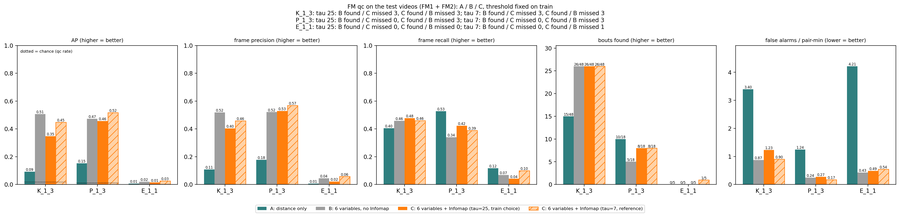

  fig figures/02_pr__FM__tau25-sm124-prior50__test.png


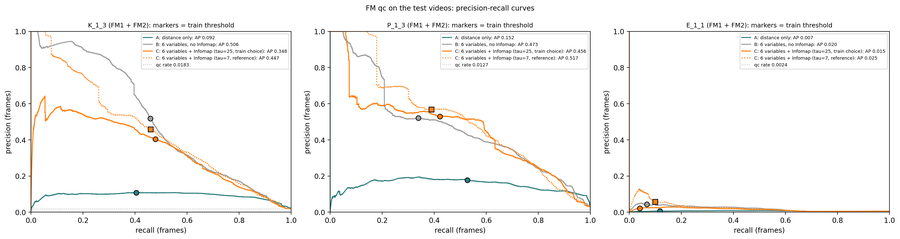

  fig figures/02_tau_effect__FM__tau25-sm124-prior50__test.png


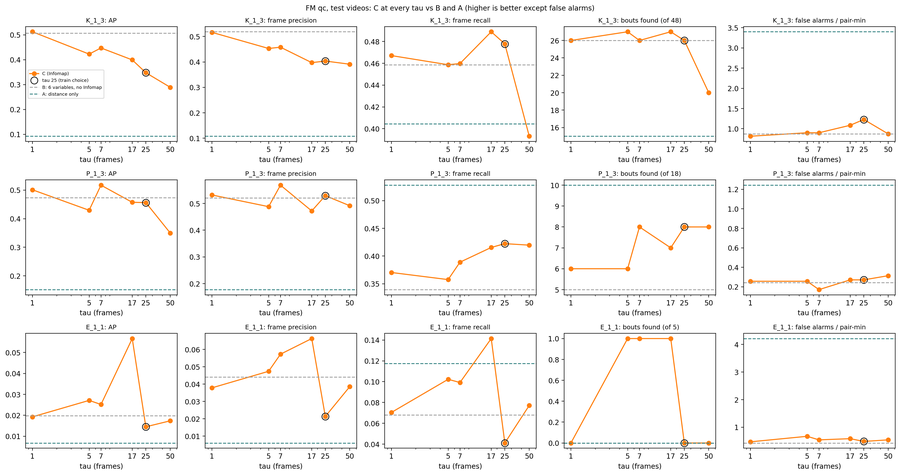

In [12]:
# Step 2a: FM quick circle.
L.clear_log("02")
RESULTS["qc"] = run_target("qc")
show_tables(RESULTS["qc"])
fig_main_table(RESULTS["qc"])
fig_pr_tau(RESULTS["qc"])
L.log("02", "done")

## Step 3 — MM 攻击（att = attack + attempted att + Dash），同样的 A / B / C

和 Step 2a 完全相同的流程，只是单元换成 MM、类别换成 att，平滑窗口 5 帧（v3b 的 att 设置）。C 的主 τ = 7（v3b 训练集上 MM att 的 LOEO 最佳）；参照 τ = 1、3、5、17、20（20 = MM 的论文规则 τ；3 = v3 里 att 最好的 τ，图中作参照画出）。每个视频只评估 M1M2 这一个顺序（M2M1 是同一对鱼）。训练时两个顺序都用（同 v3b）。

**输出 / 图**：同 Step 2a，前缀 `03_`、单元 `MM`。

[MM] tau 1: Infomap on 14113 states, 86241 edges, 2651436 transitions
[MM] tau 3: Infomap on 14111 states, 118953 edges, 2650124 transitions
[MM] tau 5: Infomap on 14111 states, 141623 edges, 2648872 transitions


[MM] tau 7: clusters from v3b (03_state_clusters__MM__tau7-dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__train.csv)
[MM] tau 17: clusters from v3b (03_state_clusters__MM__tau17-dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__train.csv)
[MM] tau 20: clusters from v3b (03_state_clusters__MM__tau20-dmax40-bd6-of-bz4-bth8-bs3-ct-minv0__train.csv)


[MM] 3 Infomap runs x 200 trials: 180 s
[MM] tau 1: 6989 clusters
[MM] tau 3: 3125 clusters
[MM] tau 5: 2190 clusters
[MM] tau 7: 1851 clusters
[MM] tau 17: 1381 clusters
[MM] tau 20: 1343 clusters


[att] A distance bins (2 mm): units 152 (seen in train 151), train rate 0.0014, threshold 0.0142, train F1 0.052


[att] B 6-variable microstates: units 16130 (seen in train 13784), train rate 0.0014, threshold 0.0445, train F1 0.321


C_tau1: frames with a state outside the graph: train 0, test 13880
[att] C_tau1 6-variable microstates + Infomap (tau=1, reference): units 6990 (seen in train 6943), train rate 0.0014, threshold 0.0735, train F1 0.260


... (3 outputs left out)

C_tau17: frames with a state outside the graph: train 2, test 13894
[att] C_tau17 6-variable microstates + Infomap (tau=17, reference): units 1382 (seen in train 1382), train rate 0.0014, threshold 0.0357, train F1 0.144


C_tau20: frames with a state outside the graph: train 10, test 13912
[att] C_tau20 6-variable microstates + Infomap (tau=20, reference): units 1344 (seen in train 1344), train rate 0.0014, threshold 0.0336, train F1 0.148
[att] B: test positive frames in states with 0-1 labelled train frames: 2 (0.1%)
[att] B: test positive frames in states with 1-50 labelled train frames: 694 (47.6%)
[att] B: test positive frames in states with 50-500 labelled train frames: 466 (32.0%)
[att] B: test positive frames in states with 500-inf labelled train frames: 296 (20.3%)


[att] check against v3b (A, C, C_tau17, C_tau20): max |AP difference| 1.24e-05, max |threshold difference| 8.85e-17
  csv data/03_abc_all_tau__MM__tau7-sm5-prior50__test.csv  rows 24
  csv data/03_abc_pooled__MM__tau7-sm5-prior50__test.csv  rows 8
  csv data/03_abc_bouts__MM__tau7-sm5-prior50__test.csv  rows 54
  csv data/03_abc_main_table__MM__tau7-sm5-prior50__test.csv  rows 12
Requested table (att; C = Infomap at tau 7; ['C_tau3'] = reference):
video method    AP  positive rate (AP chance)  frame precision  frame recall  bouts found  bouts  false-alarm intervals  false alarms / pair-min  found by B, missed by C  found by C, missed by B
K_1_3      A 0.008                      0.001            0.012         0.362            7     16                    196                    5.600                      NaN                      NaN
K_1_3      B 0.014                      0.001            0.025         0.179            4     16                    214                    6.114              

  fig figures/03_abc_main_table__MM__tau7-sm5-prior50__test.png


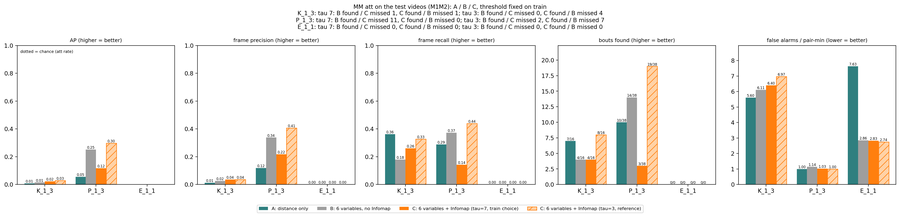

  fig figures/03_pr__MM__tau7-sm5-prior50__test.png


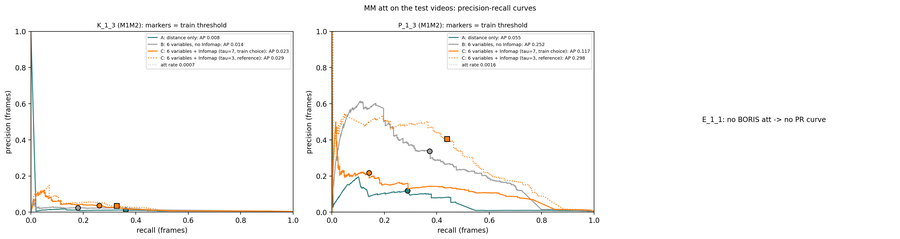

  fig figures/03_tau_effect__MM__tau7-sm5-prior50__test.png


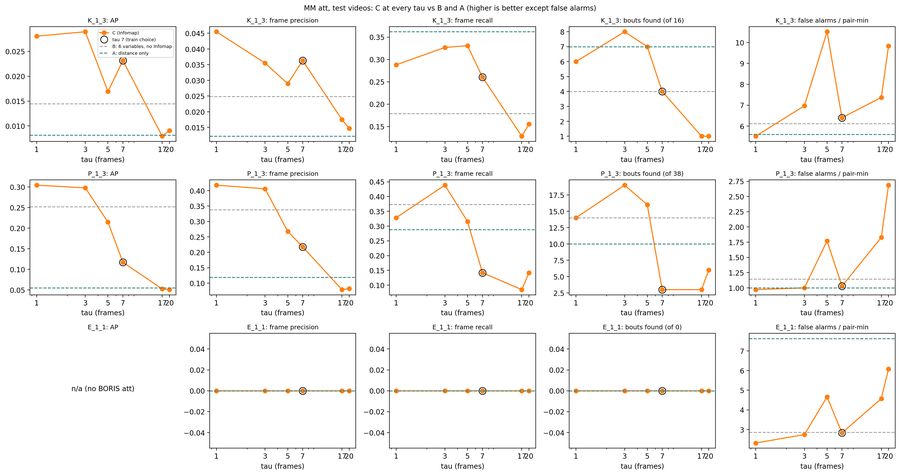

In [13]:
# Step 3: MM attack.
L.clear_log("03")
RESULTS["att"] = run_target("att")
show_tables(RESULTS["att"])
fig_main_table(RESULTS["att"])
fig_pr_tau(RESULTS["att"])
L.log("03", "done")

## Step 4 — 误差分析：误报在哪里、漏报怎么漏的、漏掉的 bout 有多长

对 qc（FM）和 att（MM），方法 A、B、C（主 τ），每个测试视频（同 Step 2 的 `eval_copies`）：

- **误报帧离 BORIS 区间多远**：每个被判为该行为、但 BORIS 不是该行为的帧，到同一配对里最近的该行为帧的距离。≤ 0.5 s = 紧挨着 BORIS 区间（多半是起止边界的差别）；0.5–2 s = 附近；> 2 s = 完全不同的地方。另外按该帧的 BORIS 标签分：`none`（没有任何标注）还是别的类别（如 qc 检测里的 att、wrap）。
- **漏掉的帧怎么漏的**：没有状态（审核屏蔽 / 跟踪丢失，打不了分）；在**已检出** bout 的边缘（bout 找到了，只是首尾几帧没判出）；在**完全漏掉**的 bout 里。
- **不同长度 bout 的检出率**：bout 按时长分组（`bout_bins_s`），每组检出数 / 总数。另外给出"只要有 1 帧被判出就算找到"的宽松检出率。
- **报警区间的正确率**：所有报警区间中，碰到真实行为的比例。

**图**：
- `04_errors__<unit>`：每行一个测试视频。第 1 列 = 误报帧按距离分组（帧数，堆叠）；第 2 列 = 漏报帧按原因分组；第 3 列 = 各长度组的 bout 检出率（柱上数字 = 检出 / 总数）。
- `04_raster__<unit>`：整段视频的时间轴。每个配对 4 行：BORIS（黑）、A、B、C 的判定（彩色）。一眼看出误报是集中在 BORIS 区间附近还是散在别处。
- `04_zoom__<unit>`：行为最密集的一段（qc 60 s、att 20 s）。灰色底 = BORIS 区间；三条线 = A、B、C 的平滑分数除以各自阈值（> 1 = 判为该行为，虚线 = 1）。

**输出**：`data/04_errors__all__base__test.csv`、`data/04_bout_length__all__base__test.csv`。

In [14]:
# Step 4: where false positives are, how frames are missed, which bouts are missed.
L.clear_log("04")


def runs_of(mask):
    a0, a1 = S.bool_runs(np.asarray(mask, bool))
    return list(zip(a0, a1 - a0))


err_rows, len_rows = [], []
for target, R in RESULTS.items():
    te = R["mic"]["test"]
    yte = R["Y"]["test"]
    lab_te = R["base_lab"]["test"]
    has_state = te["state"] >= 0
    bins = R["cfg"]["bout_bins_s"]
    for e in R["exp_names"]:
        fps = R["fps"][e]
        m_all = eval_mask(R, e)
        for key in ("A", "B", "C"):
            thr = R["fit"][key]["threshold"]
            row = {"target": target, "unit": R["unit"], "video": exp_short(e), "method": key}
            agg = {k: 0 for k in ("pred", "tp", "fp", "fp_near", "fp_mid", "fp_far", "fp_none", "fp_other_class",
                                  "fn", "fn_no_state", "fn_edge", "fn_missed_bout", "alarms", "alarms_good",
                                  "bouts", "bouts_found", "bouts_any_overlap")}
            lens = []
            for ci in R["eval_ci"]:
                m = m_all & (te["copy"] == ci)
                y = yte[m]
                lab = lab_te[m]
                hs = has_state[m]
                pred = R["sm_te"][key][m] >= thr
                blk = np.zeros(len(y), np.int64)
                pos = np.flatnonzero(y == 1)
                fp_idx = np.flatnonzero(pred & (y == 0))
                if len(pos):
                    j = np.clip(np.searchsorted(pos, fp_idx), 1, len(pos)) - 1
                    d = np.minimum(np.abs(fp_idx - pos[j]), np.abs(pos[np.clip(j + 1, 0, len(pos) - 1)] - fp_idx)) / fps
                else:
                    d = np.full(len(fp_idx), np.inf)
                agg["pred"] += int((pred & (y >= 0)).sum())
                agg["tp"] += int((pred & (y == 1)).sum())
                agg["fp"] += len(fp_idx)
                agg["fp_near"] += int((d <= FP_DIST_S[0]).sum())
                agg["fp_mid"] += int(((d > FP_DIST_S[0]) & (d <= FP_DIST_S[1])).sum())
                agg["fp_far"] += int((d > FP_DIST_S[1]).sum())
                agg["fp_none"] += int((lab[fp_idx] == "none").sum())
                agg["fp_other_class"] += int((lab[fp_idx] != "none").sum())
                bl = bout_list(y, pred, blk)
                fn = (y == 1) & ~pred
                agg["fn"] += int(fn.sum())
                agg["fn_no_state"] += int((fn & ~hs).sum())
                for a, b, f in bl:
                    seg = fn[a:b] & hs[a:b]
                    agg["fn_edge" if f else "fn_missed_bout"] += int(seg.sum())
                    agg["bouts"] += 1
                    agg["bouts_found"] += int(f)
                    agg["bouts_any_overlap"] += int(pred[a:b].any())
                    lens.append(((b - a) / fps, f))
                good, n_pred = P4.bout_precision(y, pred, blk)
                agg["alarms"] += n_pred
                agg["alarms_good"] += good
            row.update(agg)
            row["fp_near_percent"] = 100 * agg["fp_near"] / max(agg["fp"], 1)
            row["fp_far_percent"] = 100 * agg["fp_far"] / max(agg["fp"], 1)
            row["alarm_precision"] = agg["alarms_good"] / max(agg["alarms"], 1)
            row["bout_recall_any_overlap"] = agg["bouts_any_overlap"] / max(agg["bouts"], 1)
            err_rows.append(row)
            for lo, hi in zip(bins[:-1], bins[1:]):
                sel = [f for ln, f in lens if lo <= ln < hi]
                len_rows.append({"target": target, "unit": R["unit"], "video": exp_short(e), "method": key,
                                 "bin": f"{lo:g}-{hi:g} s" if hi < 1e8 else f">= {lo:g} s",
                                 "bouts": len(sel), "found": int(sum(sel))})
ERR = pd.DataFrame(err_rows)
LEN = pd.DataFrame(len_rows)
L.save_csv(ERR, "04", "errors", "all", "base", "test")
L.save_csv(LEN, "04", "bout_length", "all", "base", "test")
cols = ["target", "video", "method", "pred", "tp", "fp", "fp_near", "fp_mid", "fp_far", "fp_none", "fp_other_class",
        "fn", "fn_no_state", "fn_edge", "fn_missed_bout", "bouts", "bouts_found", "bouts_any_overlap",
        "alarms", "alarms_good", "alarm_precision"]
print(ERR[cols].round(3).to_string(index=False))
print()
print(LEN.pivot_table(index=["target", "video", "bin"], columns="method", values="found", aggfunc="sum")
      .join(LEN[LEN.method == "A"].set_index(["target", "video", "bin"])["bouts"]).to_string())

  csv data/04_errors__all__base__test.csv  rows 18
  csv data/04_bout_length__all__base__test.csv  rows 72
target video method  pred   tp    fp  fp_near  fp_mid  fp_far  fp_none  fp_other_class   fn  fn_no_state  fn_edge  fn_missed_bout  bouts  bouts_found  bouts_any_overlap  alarms  alarms_good  alarm_precision
    qc K_1_3      A 47945 5163 42782     3585    5604   33593    42782               0 7602           11      716            6875     48           15                 41     283           45            0.159
    qc K_1_3      B 11287 5854  5433      757     432    4244     4654             779 6911           10     1519            5382     48           26                 39     100           39            0.390
    qc K_1_3      C 15117 6099  9018      662    1209    7147     9018               0 6666            3     1563            5100     48           26                 40     130           44            0.338
    qc P_1_3      A 16448 2924 13524      695    1070   11759    

  fig figures/04_errors__FM__tau25__test.png


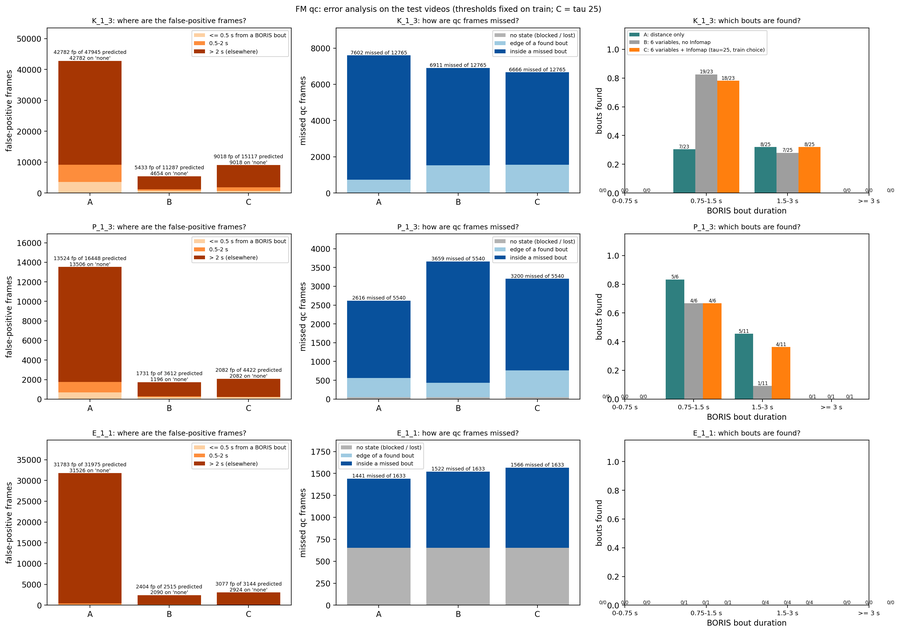

  fig figures/04_raster__FM__tau25__test.png


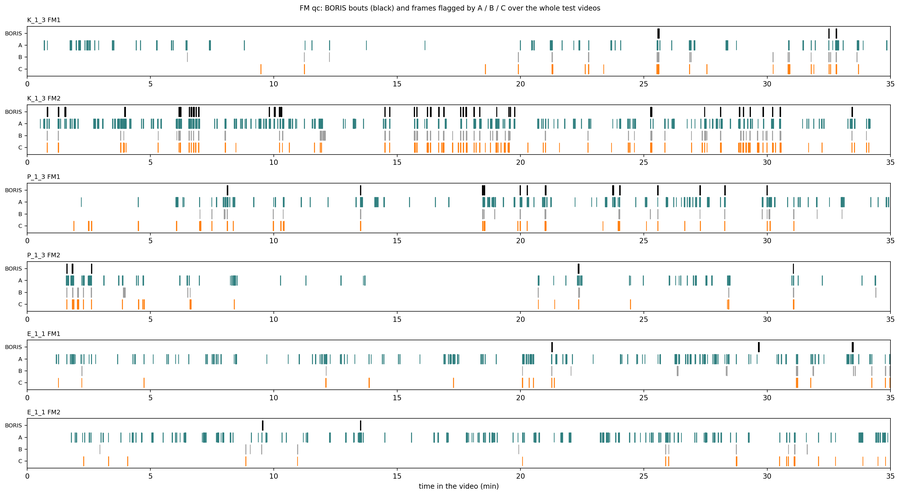

  fig figures/04_zoom__FM__tau25__test.png


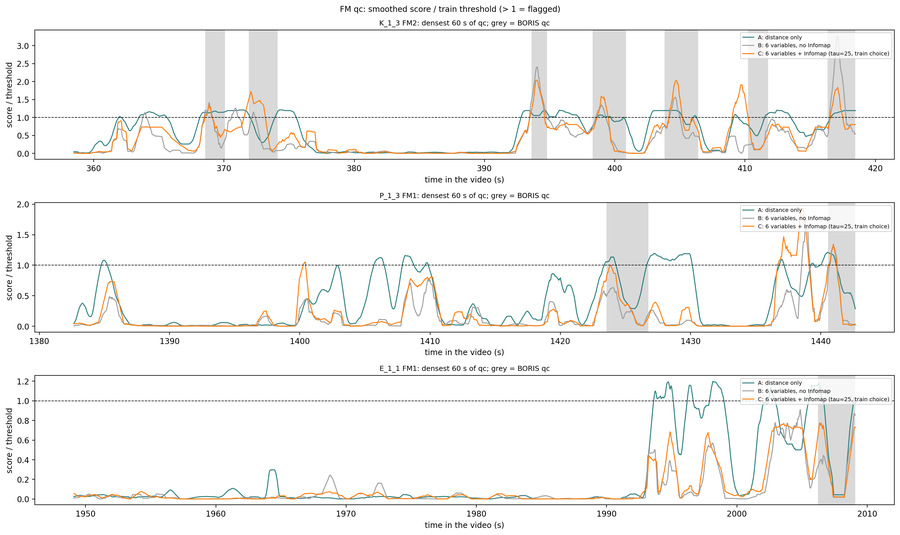

  fig figures/04_errors__MM__tau7__test.png


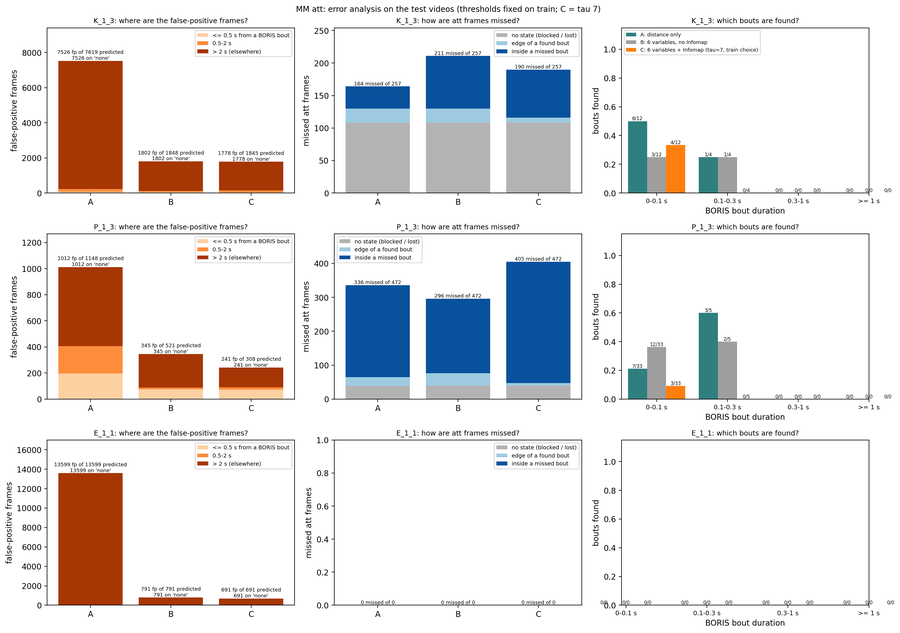

  fig figures/04_raster__MM__tau7__test.png


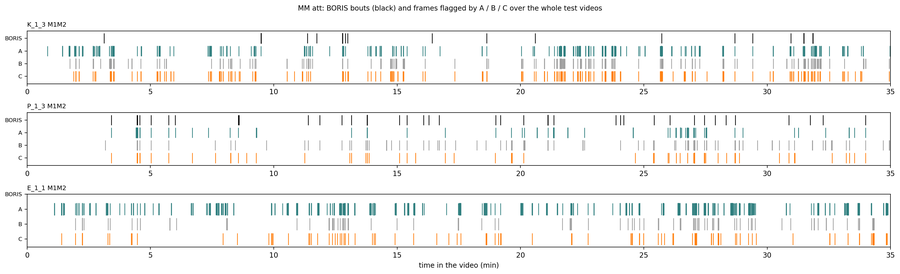

  fig figures/04_zoom__MM__tau7__test.png


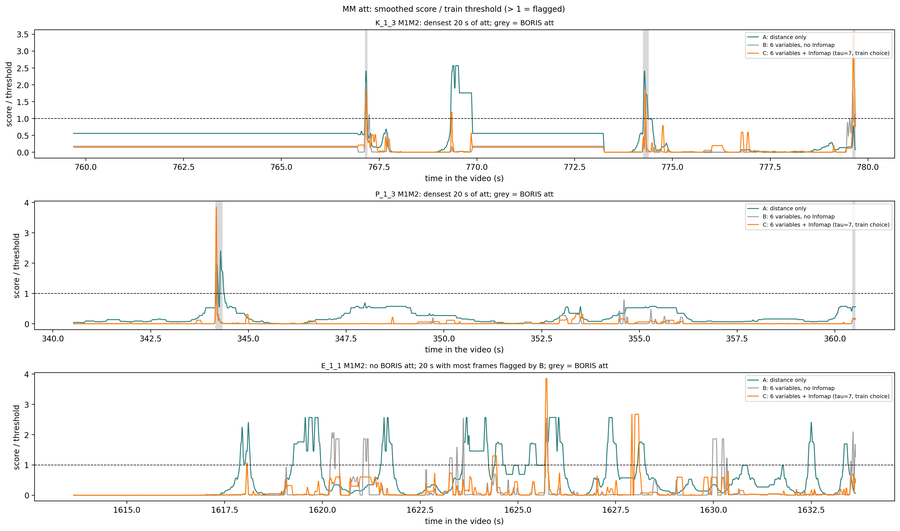

In [15]:
# Step 4 (figures): error breakdown, whole-video raster, densest window.
for target, R in RESULTS.items():
    E = ERR[ERR.target == target]
    Lb = LEN[LEN.target == target]
    vids = [exp_short(e) for e in R["exp_names"]]
    meth = ["A", "B", "C"]
    fig, axes = plt.subplots(len(vids), 3, figsize=(16, 3.8 * len(vids)), squeeze=False)
    for i, v in enumerate(vids):
        d = E[E.video == v].set_index("method").loc[meth]
        ax = axes[i, 0]
        bottom = np.zeros(len(meth))
        for col, nm, c in (("fp_near", f"<= {FP_DIST_S[0]:g} s from a BORIS bout", "#fdd0a2"),
                           ("fp_mid", f"{FP_DIST_S[0]:g}-{FP_DIST_S[1]:g} s", "#fd8d3c"),
                           ("fp_far", f"> {FP_DIST_S[1]:g} s (elsewhere)", "#a63603")):
            ax.bar(meth, d[col], bottom=bottom, color=c, label=nm)
            bottom += d[col].to_numpy()
        for k, mth in enumerate(meth):
            ax.text(k, bottom[k], f"{int(d.loc[mth, 'fp'])} fp of {int(d.loc[mth, 'pred'])} predicted\n"
                                  f"{int(d.loc[mth, 'fp_none'])} on 'none'", ha="center", va="bottom", fontsize=6.5)
        ax.set_ylim(0, bottom.max() * 1.25 + 1)
        ax.set_ylabel("false-positive frames")
        ax.set_title(f"{v}: where are the false-positive frames?", fontsize=9)
        ax.legend(fontsize=7)
        ax = axes[i, 1]
        bottom = np.zeros(len(meth))
        for col, nm, c in (("fn_no_state", "no state (blocked / lost)", "0.7"),
                           ("fn_edge", "edge of a found bout", "#9ecae1"),
                           ("fn_missed_bout", "inside a missed bout", "#08519c")):
            ax.bar(meth, d[col], bottom=bottom, color=c, label=nm)
            bottom += d[col].to_numpy()
        for k, mth in enumerate(meth):
            ax.text(k, bottom[k], f"{int(d.loc[mth, 'fn'])} missed of {int(d.loc[mth, 'tp'] + d.loc[mth, 'fn'])}",
                    ha="center", va="bottom", fontsize=6.5)
        ax.set_ylim(0, bottom.max() * 1.2 + 1)
        ax.set_ylabel(f"missed {target} frames")
        ax.set_title(f"{v}: how are {target} frames missed?", fontsize=9)
        ax.legend(fontsize=7)
        ax = axes[i, 2]
        lb = Lb[Lb.video == v]
        bin_names = list(dict.fromkeys(lb["bin"]))
        w = 0.27
        for k, mth in enumerate(meth):
            q = lb[lb.method == mth].set_index("bin").loc[bin_names]
            rate = np.where(q.bouts > 0, q.found / q.bouts.clip(lower=1), np.nan)
            x = np.arange(len(bin_names)) + (k - 1) * w
            ax.bar(x, rate, width=w, color=METHOD_COLOR[mth], label=method_label(R, mth) if i == 0 else None)
            for xi, f_, n_ in zip(x, q.found, q.bouts):
                ax.text(xi, (f_ / n_ if n_ else 0), f"{f_}/{n_}", ha="center", va="bottom", fontsize=6)
        ax.set_xticks(np.arange(len(bin_names)), bin_names, fontsize=8)
        ax.set_ylim(0, 1.15)
        ax.set_xlabel("BORIS bout duration")
        ax.set_ylabel("bouts found")
        ax.set_title(f"{v}: which bouts are found?", fontsize=9)
        if i == 0:
            ax.legend(fontsize=6.5, loc="upper left")
    fig.suptitle(f"{R['unit']} {target}: error analysis on the test videos (thresholds fixed on train; "
                 f"C = tau {R['main']})", fontsize=10)
    fig.tight_layout()
    show(L.save_fig(fig, "04", "errors", R["unit"], {"tau": R["main"]}, "test"))

    # whole-video raster
    te = R["mic"]["test"]
    yte = R["Y"]["test"]
    lanes = [(e, ci) for e in R["exp_names"] for ci in R["eval_ci"]]
    fig, axes = plt.subplots(len(lanes), 1, figsize=(18, 1.5 * len(lanes) + 1), squeeze=False)
    for ax, (e, ci) in zip(axes[:, 0], lanes):
        m = eval_mask(R, e) & (te["copy"] == ci)
        t0 = te["frame"][m][0]
        fps = R["fps"][e]
        rows_ = [("BORIS", yte[m] == 1, "k")] + [(k, R["sm_te"][k][m] >= R["fit"][k]["threshold"], METHOD_COLOR[k])
                                                for k in ("A", "B", "C")]
        for r_, (nm, mk, col) in enumerate(rows_):
            spans = [((a) / fps / 60.0, max(n, 1) / fps / 60.0) for a, n in runs_of(mk)]
            ax.broken_barh(spans, (len(rows_) - 1 - r_ - 0.4, 0.8), color=col)
        ax.set_yticks(np.arange(len(rows_)), [r[0] for r in rows_][::-1], fontsize=8)
        ax.set_xlim(0, m.sum() / fps / 60.0)
        ax.set_title(f"{exp_short(e)} {R['copy_names'][ci]}", fontsize=9, loc="left")
    axes[-1, 0].set_xlabel("time in the video (min)")
    fig.suptitle(f"{R['unit']} {target}: BORIS bouts (black) and frames flagged by A / B / C over the whole test videos",
                 fontsize=10)
    fig.tight_layout()
    show(L.save_fig(fig, "04", "raster", R["unit"], {"tau": R["main"]}, "test"))

    # densest window
    fig, axes = plt.subplots(len(R["exp_names"]), 1, figsize=(16, 3.2 * len(R["exp_names"])), squeeze=False)
    win = R["cfg"]["zoom_s"]
    for ax, e in zip(axes[:, 0], R["exp_names"]):
        fps = R["fps"][e]
        best = None
        for ci in R["eval_ci"]:
            m = eval_mask(R, e) & (te["copy"] == ci)
            y1 = (yte[m] == 1).astype(float)
            cnt = pd.Series(y1).rolling(int(win * fps), min_periods=1).sum().to_numpy()
            if best is None or cnt.max() > best[0]:
                best = (cnt.max(), ci, int(np.argmax(cnt)))
        _c, ci, end = best
        what = f"densest {win:g} s of {target}"
        if _c == 0:   # no BORIS bout of this class: show the window with most frames flagged by B
            for ci2 in R["eval_ci"]:
                m2 = eval_mask(R, e) & (te["copy"] == ci2)
                cnt = pd.Series((R["sm_te"]["B"][m2] >= R["fit"]["B"]["threshold"]).astype(float)).rolling(
                    int(win * fps), min_periods=1).sum().to_numpy()
                if cnt.max() >= _c:
                    _c, ci, end = cnt.max(), ci2, int(np.argmax(cnt))
            what = f"no BORIS {target}; {win:g} s with most frames flagged by B"
        m = eval_mask(R, e) & (te["copy"] == ci)
        n = int(win * fps)
        sl = slice(max(0, end - n + 1), end + 1)
        t = np.arange(sl.start, sl.stop) / fps
        for a, k in runs_of(yte[m][sl] == 1):
            ax.axvspan(t[a], t[min(a + k - 1, len(t) - 1)], color="0.85", lw=0)
        for k in ("A", "B", "C"):
            ax.plot(t, R["sm_te"][k][m][sl] / R["fit"][k]["threshold"], color=METHOD_COLOR[k], lw=1.2,
                    label=method_label(R, k))
        ax.axhline(1.0, color="k", ls="--", lw=0.8)
        ax.set_xlabel("time in the video (s)")
        ax.set_ylabel("score / threshold")
        ax.set_title(f"{exp_short(e)} {R['copy_names'][ci]}: {what}; grey = BORIS {target}",
                     fontsize=9)
        ax.legend(fontsize=7, loc="upper right")
    fig.suptitle(f"{R['unit']} {target}: smoothed score / train threshold (> 1 = flagged)", fontsize=10)
    fig.tight_layout()
    show(L.save_fig(fig, "04", "zoom", R["unit"], {"tau": R["main"]}, "test"))
L.log("04", "done")

## Step 5 — 文件清单

In [16]:
print("output folder:", L.root)
for sub in ("figures", "data"):
    files = sorted(p.name for p in (L.root / sub).iterdir())
    print(f"\n{sub}/ ({len(files)} files)")
    for f in files:
        print("  ", f)

output folder: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\outputs\20261109_pca_origin_qc_abc_v6

figures/ (28 files)
   01_pca_corr__FM__base__train.png
   01_pca_corr__MM__base__train.png
   01_pca_loadings__FM__base__train.png
   01_pca_loadings__MM__base__train.png
   01_pca_variance__FM__base__train.png
   01_pca_variance__MM__base__train.png
   01b_pca_modes__FM__base__train.png
   01b_pca_modes__MM__base__train.png
   01b_pca_modes_body__FM__base__train.png
   01b_pca_modes_body__MM__base__train.png
   01b_pca_modes_ref__FM__base__train.png
   01b_pca_modes_ref__MM__base__train.png
   01b_pca_scatter__FM__base__train.png
   01b_pca_scatter__MM__base__train.png
   01d_loadings_three_origins__FM__base__train.png
   01d_loadings_three_origins__MM__base__train.png
   02_abc_main_table__FM__tau25-sm124-prior50__test.png
   02_pr__FM__tau25-sm124-prior50__test.png
   02_tau_effect__FM__tau25-sm124-prior50__test.png
   03_abc_main_table__MM__tau7-sm5-prior50__test.p